# **Used Car Price Prediction Using Machine Learning Regression**

## **1. Project Overview**

### **Objective**

The objective of this project is to develop a machine learning regression model capable of predicting the resale price of used cars based on various vehicle characteristics.

### **Problem Statement**

Determining the resale value of a used car can be challenging because its price depends on several factors, including manufacturing year, kilometres driven, fuel type, transmission type, ownership history and other specifications.This project aims to analyze these factors and develop predictive models that can estimate used car prices accurately.

### **Dataset**

The project uses the CarDekho Used Car Dataset, which contains information about previously owned vehicles in the Indian automobile market.

### **Target Variable**

`selling_price`

### **Technology Stack**

* Python
* Pandas
* NumPy
* Matplotlib
* Seaborn
* Scikit-Learn
* Jupyter Notebook


## **2. Importing Libraries**

In [37]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

# Visualization settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

## **3. Loading The Dataset**

In [38]:
# Define project directory
PROJECT_DIR = Path.cwd()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

# Define dataset path
DATA_PATH = PROJECT_DIR / "data" / "raw" / "Car details v3.csv"

# Load dataset
df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")

Dataset loaded successfully!


## **4. Inspecting The Dataset**

In [39]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

df.head()
df.tail()
df.info()
df.describe(include="all").T
print("Dataset columns:")
print(df.columns.tolist())


Number of rows: 8128
Number of columns: 13
<class 'pandas.DataFrame'>
RangeIndex: 8128 entries, 0 to 8127
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   name           8128 non-null   str    
 1   year           8128 non-null   int64  
 2   selling_price  8128 non-null   int64  
 3   km_driven      8128 non-null   int64  
 4   fuel           8128 non-null   str    
 5   seller_type    8128 non-null   str    
 6   transmission   8128 non-null   str    
 7   owner          8128 non-null   str    
 8   mileage        7907 non-null   str    
 9   engine         7907 non-null   str    
 10  max_power      7913 non-null   str    
 11  torque         7906 non-null   str    
 12  seats          7907 non-null   float64
dtypes: float64(1), int64(3), str(9)
memory usage: 825.6 KB
Dataset columns:
['name', 'year', 'selling_price', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_pow

## **5. Initial Data Quality Assessment**

In [40]:
missing_values = pd.DataFrame({
    "Missing_Count": df.isnull().sum(),
    "Missing_Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values.sort_values(
    by="Missing_Percentage",
    ascending=False
)

,Missing_Count,Missing_Percentage
torque,222,2.73
seats,221,2.72
engine,221,2.72
mileage,221,2.72
max_power,215,2.65
fuel,0,0.00
km_driven,0,0.00
selling_price,0,0.00
year,0,0.00
name,0,0.00


In [41]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 1202


In [42]:
numerical_columns = df.select_dtypes(include=["number"]).columns.tolist()

categorical_columns = df.select_dtypes(include=["str", "object", "category"]).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['year', 'selling_price', 'km_driven', 'seats']
Categorical columns: ['name', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque']


In [43]:
print("Target variable: selling_price")

print(df["selling_price"].describe())

print("\nUnique selling prices:")
print(df["selling_price"].nunique())

Target variable: selling_price
count    8.128000e+03
mean     6.382718e+05
std      8.062534e+05
min      2.999900e+04
25%      2.549990e+05
50%      4.500000e+05
75%      6.750000e+05
max      1.000000e+07
Name: selling_price, dtype: float64

Unique selling prices:
677


In [44]:
print("Duplicate records:", df.duplicated().sum())

print("\nUnique values in categorical columns:")

for col in ["fuel", "seller_type", "transmission", "owner"]:
    print(f"\n{col}:")
    print(df[col].value_counts())

print("\nSample vehicle specifications:")
display(df[["name", "mileage", "engine", "max_power", "torque", "seats"]].head(10))

Duplicate records: 1202

Unique values in categorical columns:

fuel:
fuel
Diesel    4402
Petrol    3631
CNG         57
LPG         38
Name: count, dtype: int64

seller_type:
seller_type
Individual          6766
Dealer              1126
Trustmark Dealer     236
Name: count, dtype: int64

transmission:
transmission
Manual       7078
Automatic    1050
Name: count, dtype: int64

owner:
owner
First Owner             5289
Second Owner            2105
Third Owner              555
Fourth & Above Owner     174
Test Drive Car             5
Name: count, dtype: int64

Sample vehicle specifications:


,name,mileage,engine,max_power,torque,seats
0,Maruti Swift Dzire VDI,23.4 kmpl,1248 CC,74 bhp,190Nm@ 2000rpm,5.0
1,Skoda Rapid 1.5 TDI Ambition,21.14 kmpl,1498 CC,103.52 bhp,250Nm@ 1500-2500rpm,5.0
2,Honda City 2017-2020 EXi,17.7 kmpl,1497 CC,78 bhp,"12.7@ 2,700(kgm@ rpm)",5.0
3,Hyundai i20 Sportz Diesel,23.0 kmpl,1396 CC,90 bhp,22.4 kgm at 1750-2750rpm,5.0
4,Maruti Swift VXI BSIII,16.1 kmpl,1298 CC,88.2 bhp,"11.5@ 4,500(kgm@ rpm)",5.0
5,Hyundai Xcent 1.2 VTVT E Plus,20.14 kmpl,1197 CC,81.86 bhp,113.75nm@ 4000rpm,5.0
6,Maruti Wagon R LXI DUO BSIII,17.3 km/kg,1061 CC,57.5 bhp,"7.8@ 4,500(kgm@ rpm)",5.0
7,Maruti 800 DX BSII,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0
8,Toyota Etios VXD,23.59 kmpl,1364 CC,67.1 bhp,170Nm@ 1800-2400rpm,5.0
9,Ford Figo Diesel Celebration Edition,20.0 kmpl,1399 CC,68.1 bhp,160Nm@ 2000rpm,5.0


In [45]:
# Display the first 10 duplicate records
duplicate_records = df[df.duplicated(keep=False)]

print("Total rows involved in duplication:", len(duplicate_records))

display(duplicate_records.head(10))

Total rows involved in duplication: 1827


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN
32,Maruti Omni 8 Seater BSIV,2012,150000,35000,Petrol,Individual,Manual,Second Owner,14.0 kmpl,796 CC,35 bhp,6.1kgm@ 3000rpm,5.0
33,Hyundai i20 1.2 Asta Dual Tone,2018,730000,2388,Petrol,Individual,Manual,First Owner,18.6 kmpl,1197 CC,81.83 bhp,114.7Nm@ 4000rpm,5.0
34,Maruti Vitara Brezza LDi,2017,650000,16200,Diesel,Individual,Manual,First Owner,24.3 kmpl,1248 CC,88.5 bhp,200Nm@ 1750rpm,5.0
35,Maruti Alto 800 CNG LXI Optional,2019,330000,10000,CNG,Individual,Manual,Second Owner,33.44 km/kg,796 CC,40.3 bhp,60Nm@ 3500rpm,4.0
36,Maruti Alto K10 VXI Airbag,2019,366000,15000,Petrol,Individual,Manual,First Owner,23.95 kmpl,998 CC,67.1 bhp,90Nm@ 3500rpm,5.0
37,Hyundai Verna VTVT 1.6 SX Option,2019,1149000,5000,Petrol,Individual,Manual,First Owner,17.0 kmpl,1591 CC,121.3 bhp,151Nm@ 4850rpm,5.0
38,Datsun GO D,2016,150000,42000,Petrol,Individual,Manual,First Owner,20.63 kmpl,1198 CC,67 bhp,104Nm@ 4000rpm,5.0
39,Tata Safari DICOR 2.2 LX 4x2,2011,425000,60000,Diesel,Individual,Manual,Second Owner,13.93 kmpl,2179 CC,138.03 bhp,320Nm@ 1700-2700rpm,7.0
40,Maruti 800 Std,2012,150000,76000,Petrol,Individual,Manual,First Owner,16.1 kmpl,796 CC,37 bhp,59Nm@ 2500rpm,4.0


In [46]:
print("Total unique vehicle names:", df["name"].nunique())

print("\nFirst 20 vehicle names:")
print(df["name"].unique()[:20])

Total unique vehicle names: 2058

First 20 vehicle names:
<StringArray>
[              'Maruti Swift Dzire VDI',
         'Skoda Rapid 1.5 TDI Ambition',
             'Honda City 2017-2020 EXi',
            'Hyundai i20 Sportz Diesel',
               'Maruti Swift VXI BSIII',
        'Hyundai Xcent 1.2 VTVT E Plus',
         'Maruti Wagon R LXI DUO BSIII',
                   'Maruti 800 DX BSII',
                     'Toyota Etios VXD',
 'Ford Figo Diesel Celebration Edition',
      'Renault Duster 110PS Diesel RxL',
                        'Maruti Zen LX',
               'Maruti Swift Dzire VDi',
                 'Maruti Swift 1.3 VXi',
             'Maruti Wagon R LXI Minor',
 'Mahindra KUV 100 mFALCON G80 K8 5str',
               'Maruti Ertiga SHVS VDI',
            'Hyundai i20 1.4 CRDi Asta',
                       'Maruti Alto LX',
  'Hyundai i20 2015-2017 Asta 1.4 CRDi']
Length: 20, dtype: str


In [47]:
print("Mileage formats:")
print(df["mileage"].dropna().tail(15).tolist())

print("\nEngine formats:")
print(df["engine"].dropna().unique()[:15])

print("\nMaximum power formats:")
print(df["max_power"].dropna().unique()[:15])

print("\nTorque formats:")
print(df["torque"].dropna().unique()[:20])

Mileage formats:
['12.8 kmpl', '19.7 kmpl', '16.1 kmpl', '23.95 kmpl', '26.59 kmpl', '18.5 kmpl', '20.51 kmpl', '17.92 kmpl', '18.9 kmpl', '22.54 kmpl', '18.5 kmpl', '16.8 kmpl', '19.3 kmpl', '23.57 kmpl', '23.57 kmpl']

Engine formats:
<StringArray>
['1248 CC', '1498 CC', '1497 CC', '1396 CC', '1298 CC', '1197 CC', '1061 CC',
  '796 CC', '1364 CC', '1399 CC', '1461 CC',  '993 CC', '1198 CC', '1199 CC',
  '998 CC']
Length: 15, dtype: str

Maximum power formats:
<StringArray>
[    '74 bhp', '103.52 bhp',     '78 bhp',     '90 bhp',   '88.2 bhp',
  '81.86 bhp',   '57.5 bhp',     '37 bhp',   '67.1 bhp',   '68.1 bhp',
 '108.45 bhp',     '60 bhp',   '73.9 bhp',     '67 bhp',     '82 bhp']
Length: 15, dtype: str

Torque formats:
<StringArray>
[          '190Nm@ 2000rpm',      '250Nm@ 1500-2500rpm',
    '12.7@ 2,700(kgm@ rpm)', '22.4 kgm at 1750-2750rpm',
    '11.5@ 4,500(kgm@ rpm)',        '113.75nm@ 4000rpm',
     '7.8@ 4,500(kgm@ rpm)',            '59Nm@ 2500rpm',
      '170Nm@ 1800-2400rp

In [48]:
# Preserve the original dataset
df_raw = df.copy()

# Remove exact duplicate records
df_clean = df.drop_duplicates().copy()

print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)
print("Duplicate records removed:", len(df) - len(df_clean))
print("Remaining duplicate records:", df_clean.duplicated().sum())

Original dataset shape: (8128, 13)
Cleaned dataset shape: (6926, 13)
Duplicate records removed: 1202
Remaining duplicate records: 0


In [49]:
# Check mileage units
print("Mileage unit distribution:")

print(
    df_clean["mileage"]
    .dropna()
    .str.extract(r"(kmpl|km/kg)", expand=False)
    .value_counts()
)

# Check torque unit patterns
print("\nTorque values containing Nm:")
print(df_clean["torque"].str.contains("nm", case=False, na=False).sum())

print("\nTorque values containing kgm:")
print(df_clean["torque"].str.contains("kgm", case=False, na=False).sum())

print("\nTorque values without an identifiable unit:")
print(
    df_clean[
        ~df_clean["torque"].str.contains(
            r"nm|kgm", case=False, na=False
        )
    ]["torque"].dropna().unique()[:20]
)

Mileage unit distribution:
mileage
kmpl     6631
km/kg      87
Name: count, dtype: int64

Torque values containing Nm:
6227

Torque values containing kgm:
481

Torque values without an identifiable unit:
<StringArray>
['250@ 1250-5000rpm', '510@ 1600-2400', '110(11.2)@ 4800', '210 / 1900']
Length: 4, dtype: str


## **6. Data Cleaning and Feature Engineering**
* The dataset contains several vehicle specifications stored as text rather than numerical values. These include mileage, engine capacity, maximum power and torque.
* To prepare the dataset for machine learning, these specifications must be transformed into usable numerical features.
* The preprocessing stage also extracts the mileage unit and vehicle manufacturer from the original columns.

#### **Manufacturer extraction**

In [50]:
# Extract vehicle manufacturer
df_clean["manufacturer"] = df_clean["name"].str.split().str[0]

print("Number of manufacturers:", df_clean["manufacturer"].nunique())

print("\nTop 15 manufacturers:")
print(df_clean["manufacturer"].value_counts().head(15))

Number of manufacturers: 32

Top 15 manufacturers:
manufacturer
Maruti           2165
Hyundai          1267
Mahindra          723
Tata              647
Honda             362
Ford              361
Toyota            357
Chevrolet         216
Renault           206
Volkswagen        174
Nissan             73
Skoda              70
Datsun             57
BMW                47
Mercedes-Benz      46
Name: count, dtype: int64


#### **Mileage conversion**

In [51]:
# Extract mileage unit
df_clean["mileage_unit"] = df_clean["mileage"].str.extract(
    r"(kmpl|km/kg)", expand=False
)

# Extract numerical mileage value
df_clean["mileage"] = pd.to_numeric(
    df_clean["mileage"].str.extract(r"(\d+\.?\d*)", expand=False),
    errors="coerce"
)

print(df_clean[["mileage", "mileage_unit"]].head(10))

   mileage mileage_unit
0    23.40         kmpl
1    21.14         kmpl
2    17.70         kmpl
3    23.00         kmpl
4    16.10         kmpl
5    20.14         kmpl
6    17.30        km/kg
7    16.10         kmpl
8    23.59         kmpl
9    20.00         kmpl


#### **Engine and power conversion**

In [52]:
# Extract numerical engine capacity
df_clean["engine"] = pd.to_numeric(
    df_clean["engine"].str.extract(r"(\d+\.?\d*)", expand=False),
    errors="coerce"
)

# Extract numerical maximum power
df_clean["max_power"] = pd.to_numeric(
    df_clean["max_power"].str.extract(r"(\d+\.?\d*)", expand=False),
    errors="coerce"
)

print(df_clean[["engine", "max_power"]].head(10))

   engine  max_power
0  1248.0      74.00
1  1498.0     103.52
2  1497.0      78.00
3  1396.0      90.00
4  1298.0      88.20
5  1197.0      81.86
6  1061.0      57.50
7   796.0      37.00
8  1364.0      67.10
9  1399.0      68.10


#### **Torque conversion**

In [53]:
import re

def convert_torque(value):
    if pd.isna(value):
        return np.nan

    text = str(value).lower().replace(",", "")

    match = re.search(r"(\d+\.?\d*)", text)

    if not match:
        return np.nan

    torque_value = float(match.group(1))

    # Explicit Nm values
    if "nm" in text:
        return torque_value

    # Explicit or parenthetical kgm annotation
    if "kgm" in text:

        # These malformed entries contain values already expressed in Nm
        if torque_value >= 40:
            return torque_value

        # Convert genuine kgm values to Nm
        return torque_value * 9.80665

    # Unknown unit
    return np.nan


# Recalculate from the original torque column
df_clean["torque"] = df_raw.loc[
    df_clean.index, "torque"
].apply(convert_torque)

# Flag implausibly high torque values
df_clean.loc[df_clean["torque"] > 700, "torque"] = np.nan

print(df_clean["torque"].describe())
print("\nMissing torque values:", df_clean["torque"].isnull().sum())

count    6704.000000
mean      170.275847
std        83.213927
min        42.000000
25%       110.000000
50%       160.000000
75%       200.055660
max       640.000000
Name: torque, dtype: float64

Missing torque values: 222


#### **Verify the transformations**

In [54]:
print("Updated dataset:")
display(df_clean.head())

print("\nUpdated data types:")
print(df_clean.dtypes)

print("\nMissing values after conversion:")
print(df_clean.isnull().sum())

Updated dataset:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,manufacturer,mileage_unit
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190.000000,5.0,Maruti,kmpl
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250.000000,5.0,Skoda,kmpl
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,124.544455,5.0,Honda,kmpl
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,219.668960,5.0,Hyundai,kmpl
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,112.776475,5.0,Maruti,kmpl



Updated data types:
name                 str
year               int64
selling_price      int64
km_driven          int64
fuel                 str
seller_type          str
transmission         str
owner                str
mileage          float64
engine           float64
max_power        float64
torque           float64
seats            float64
manufacturer      object
mileage_unit         str
dtype: object

Missing values after conversion:
name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          208
engine           208
max_power        206
torque           222
seats            208
manufacturer       0
mileage_unit     208
dtype: int64


#### **Investigate unusually high torque values**

In [55]:
# Find vehicles with torque greater than 600 Nm
high_torque = df_clean[df_clean["torque"] > 600].copy()

# Retrieve original torque values before conversion
high_torque["original_torque"] = df_raw.loc[
    high_torque.index, "torque"
]

display(
    high_torque[
        ["name", "original_torque", "torque", "engine", "max_power"]
    ].sort_values("torque", ascending=False)
)

,name,original_torque,torque,engine,max_power
170,Volvo XC90 T8 Excellence BSIV,640Nm@ 1740rpm,640.0,1969.0,400.00
136,Mercedes-Benz S-Class S 350 CDI,620Nm@ 1600-2400rpm,620.0,2987.0,254.79
1071,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0,2993.0,261.40
2938,BMW X7 xDrive 30d DPE,620Nm@ 1500-2500rpm,620.0,2993.0,265.00
4753,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0,2993.0,261.40
4766,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0,2993.0,261.40
6258,BMW 6 Series GT 630d Luxury Line,620Nm@ 2000-2500rpm,620.0,2993.0,261.40
2705,Mercedes-Benz M-Class ML 350 CDI,619Nm@ 1600-2400rpm,619.0,2987.0,254.80
7506,Mercedes-Benz GL-Class 350 CDI Blue Efficiency,619Nm@ 1600-2400rpm,619.0,2987.0,254.80
7808,Mercedes-Benz M-Class ML 350 CDI,619Nm@ 1600-2400rpm,619.0,2987.0,254.80


#### **Check numerical feature distributions**

In [56]:
numerical_features = [
    "selling_price",
    "year",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "torque",
    "seats"
]

display(df_clean[numerical_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
selling_price,6926.0,517270.678458,519766.985985,29999.0,250000.0,400000.00,633500.00000,10000000.0
year,6926.0,2013.420300,4.078286,1983.0,2011.0,2014.00,2017.00000,2020.0
km_driven,6926.0,73995.676437,58358.095175,1.0,40000.0,70000.00,100000.00000,2360457.0
mileage,6718.0,19.465310,4.049150,0.0,16.8,19.44,22.50000,42.0
engine,6718.0,1430.891337,493.493277,624.0,1197.0,1248.00,1498.00000,3604.0
max_power,6720.0,87.726919,31.771619,0.0,67.1,81.83,100.00000,400.0
torque,6704.0,170.275847,83.213927,42.0,110.0,160.00,200.05566,640.0
seats,6718.0,5.434653,0.984230,2.0,5.0,5.00,5.00000,14.0


#### **Investigate suspicious numerical values**

In [57]:
# Check zero and unusually low values
print("Mileage equal to zero:")
display(df_clean[df_clean["mileage"] == 0])

print("\nMaximum power equal to zero:")
display(df_clean[df_clean["max_power"] == 0])

# Check extremely high kilometres driven
print("\nHighest kilometres driven:")
display(
    df_clean.nlargest(
        10, "km_driven"
    )[["name", "year", "km_driven", "selling_price"]]
)

# Check unusually high torque
print("\nTorque above 600 Nm:")
display(
    df_clean[df_clean["torque"] > 600][
        ["name", "torque", "engine", "max_power"]
    ]
)

Mileage equal to zero:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,manufacturer,mileage_unit
644,Tata Indica Vista Aura Safire Anniversary Edition,2009,135000,28900,Petrol,Individual,Manual,Second Owner,0.0,1172.0,65.00,96.10517,5.0,Tata,kmpl
785,Hyundai Santro Xing GL,2009,120000,90000,Petrol,Individual,Manual,Second Owner,0.0,1086.0,62.00,96.10000,5.0,Hyundai,kmpl
1649,Hyundai Santro Xing GL,2008,105000,128000,Petrol,Individual,Manual,First Owner,0.0,1086.0,62.00,96.10000,5.0,Hyundai,kmpl
1676,Mercedes-Benz M-Class ML 350 4Matic,2011,1700000,110000,Diesel,Individual,Automatic,Third Owner,0.0,2987.0,165.00,NaN,5.0,Mercedes-Benz,kmpl
2137,Land Rover Freelander 2 TD4 HSE,2013,1650000,64788,Diesel,Dealer,Automatic,First Owner,0.0,2179.0,115.00,400.00000,5.0,Land,kmpl
2366,Hyundai Santro Xing (Non-AC),2010,110000,80000,Petrol,Individual,Manual,Second Owner,0.0,1086.0,62.10,96.10000,5.0,Hyundai,kmpl
2725,Hyundai Santro Xing (Non-AC),2013,184000,15000,Petrol,Individual,Manual,First Owner,0.0,1086.0,62.10,96.10000,5.0,Hyundai,kmpl
5276,Hyundai Santro Xing GL,2008,175000,40000,Petrol,Individual,Manual,First Owner,0.0,1086.0,62.00,96.10000,5.0,Hyundai,kmpl
5843,Volkswagen Polo GT TSI BSIV,2014,574000,28080,Petrol,Dealer,Automatic,First Owner,0.0,1197.0,103.25,175.00000,5.0,Volkswagen,kmpl
5846,Volkswagen Polo GT TSI BSIV,2014,575000,28100,Petrol,Dealer,Automatic,First Owner,0.0,1197.0,103.25,175.00000,5.0,Volkswagen,kmpl



Maximum power equal to zero:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,manufacturer,mileage_unit
575,Maruti Alto K10 LXI,2011,204999,97500,Petrol,Individual,Manual,First Owner,NaN,NaN,0.0,NaN,NaN,Maruti,NaN
1442,Maruti Swift Dzire VDI Optional,2017,589000,41232,Diesel,Dealer,Manual,First Owner,NaN,NaN,0.0,NaN,NaN,Maruti,NaN
2549,Tata Indica Vista Quadrajet LS,2012,240000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,0.0,NaN,NaN,Tata,NaN



Highest kilometres driven:


,name,year,km_driven,selling_price
3486,Hyundai i20 Asta 1.2,2007,2360457,550000
1810,Mahindra XUV500 W6 2WD,2012,1500000,500000
3508,Maruti Wagon R LXI Minor,2010,577414,194000
3641,Maruti Wagon R VXI BS IV,2011,500000,229999
6673,Toyota Innova 2.5 EV Diesel PS 7 Seater BSIII,2011,500000,350000
5106,Mahindra Scorpio M2DI,2011,475000,400000
5189,Toyota Innova 2.5 VX (Diesel) 7 Seater,2013,440000,750000
5467,Toyota Innova 2.5 VX (Diesel) 7 Seater BS IV,2010,426000,950000
2272,Mahindra Bolero SLE,2010,380000,260000
7102,Toyota Innova 2.5 V Diesel 8-seater,2007,376412,350000



Torque above 600 Nm:


,name,torque,engine,max_power
136,Mercedes-Benz S-Class S 350 CDI,620.0,2987.0,254.79
170,Volvo XC90 T8 Excellence BSIV,640.0,1969.0,400.00
1071,BMW 6 Series GT 630d Luxury Line,620.0,2993.0,261.40
2705,Mercedes-Benz M-Class ML 350 CDI,619.0,2987.0,254.80
2938,BMW X7 xDrive 30d DPE,620.0,2993.0,265.00
4753,BMW 6 Series GT 630d Luxury Line,620.0,2993.0,261.40
4766,BMW 6 Series GT 630d Luxury Line,620.0,2993.0,261.40
6258,BMW 6 Series GT 630d Luxury Line,620.0,2993.0,261.40
7506,Mercedes-Benz GL-Class 350 CDI Blue Efficiency,619.0,2987.0,254.80
7808,Mercedes-Benz M-Class ML 350 CDI,619.0,2987.0,254.80


#### **Correct invalid zero values**

In [58]:
# Replace invalid zero values with NaN

df_clean.loc[df_clean["mileage"] == 0, "mileage"] = np.nan

df_clean.loc[df_clean["max_power"] == 0, "max_power"] = np.nan

print("Invalid zero values handled successfully!")

print("\nMileage missing values:", df_clean["mileage"].isnull().sum())

print("Maximum power missing values:", df_clean["max_power"].isnull().sum())

Invalid zero values handled successfully!

Mileage missing values: 223
Maximum power missing values: 209


#### **Investigate the extreme kilometre value**

In [59]:
# Inspect the suspicious kilometre reading

suspicious_car = df_raw.loc[
    df_clean["km_driven"].idxmax()
]

display(suspicious_car)

name             Hyundai i20 Asta 1.2
year                             2007
selling_price                  550000
km_driven                     2360457
fuel                           Petrol
seller_type                Individual
transmission                   Manual
owner                    Second Owner
mileage                     18.6 kmpl
engine                        1197 CC
max_power                   81.83 bhp
torque               114.7Nm@ 4000rpm
seats                             5.0
Name: 3486, dtype: object

In [60]:
print("Kilometre distribution:")

display(
    df_clean["km_driven"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

Kilometre distribution:


count    6.926000e+03
mean     7.399568e+04
std      5.835810e+04
min      1.000000e+00
25%      4.000000e+04
50%      7.000000e+04
75%      1.000000e+05
90%      1.200000e+05
95%      1.569938e+05
99%      2.398628e+05
max      2.360457e+06
Name: km_driven, dtype: float64

#### **Remove the suspicious observation**

In [61]:
# Remove the suspicious kilometre reading

suspicious_index = df_clean["km_driven"].idxmax()

df_clean = df_clean.drop(index=suspicious_index).copy()

print("Suspicious observation removed.")

print("Updated dataset shape:", df_clean.shape)

print("Maximum kilometres driven:", df_clean["km_driven"].max())

Suspicious observation removed.
Updated dataset shape: (6925, 15)
Maximum kilometres driven: 1500000


#### **Verify the updated dataset**

In [62]:
print("Updated numerical summary:")

display(df_clean.describe())

Updated numerical summary:


,year,selling_price,km_driven,mileage,engine,max_power,torque,seats
count,6925.000000,6.925000e+03,6.925000e+03,6702.000000,6717.000000,6716.000000,6703.000000,6717.000000
mean,2013.421227,5.172660e+05,7.366550e+04,19.509005,1430.926158,87.766984,170.284138,5.434718
std,4.077851,5.198044e+05,5.148795e+04,3.947732,493.521763,31.726835,83.217365,0.984289
min,1983.000000,2.999900e+04,1.000000e+00,9.000000,624.000000,32.800000,42.000000,2.000000
25%,2011.000000,2.500000e+05,4.000000e+04,16.800000,1197.000000,67.100000,110.000000,5.000000
50%,2014.000000,4.000000e+05,7.000000e+04,19.490000,1248.000000,81.830000,160.000000,5.000000
75%,2017.000000,6.340000e+05,1.000000e+05,22.540000,1498.000000,100.000000,200.055660,5.000000
max,2020.000000,1.000000e+07,1.500000e+06,42.000000,3604.000000,400.000000,640.000000,14.000000


In [63]:
print("Remaining duplicate rows:", df_clean.duplicated().sum())

print("\nMissing values:")

display(
    df_clean.isnull().sum().sort_values(ascending=False)
)

Remaining duplicate rows: 0

Missing values:


mileage          223
torque           222
max_power        209
engine           208
mileage_unit     208
seats            208
name               0
transmission       0
seller_type        0
fuel               0
km_driven          0
selling_price      0
year               0
owner              0
manufacturer       0
dtype: int64

### **Handling Invalid and Extreme Values**

During data quality analysis, certain invalid and extreme values were identified in the dataset. These values were examined and handled to improve data reliability before model development.
* **Zero Mileage Values:** Records containing zero mileage were treated as missing values (NaN), as zero fuel efficiency is not a meaningful measurement for the listed vehicles.
* **Zero Maximum Power Values:** Records containing zero maximum power were also treated as missing values because they do not represent valid engine power measurements.
* **Extreme Kilometre Reading:** One record belonging to a 2007 Hyundai i20 Asta 1.2 had an unusually high kilometre reading of 2,360,457 km. Since this value was exceptionally higher than the dataset's 99th percentile (239,862.75 km), the observation was excluded as a potentially erroneous data entry.
* **Other High Kilometre Readings:** Other vehicles with relatively high kilometre readings were retained because such values can occur in heavily used vehicles and were not sufficient evidence of incorrect data.

These cleaning operations help improve the consistency and reliability of the dataset while preserving useful observations for further analysis.


### **Analyse missing values**

In [64]:
# Calculate missing values and percentages

missing_summary = pd.DataFrame({
    "Missing Values": df_clean.isnull().sum(),
    "Missing Percentage": (
        df_clean.isnull().sum() / len(df_clean) * 100
    ).round(2)
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_summary)

,Missing Values,Missing Percentage
mileage,223,3.22
torque,222,3.21
max_power,209,3.02
engine,208,3.00
mileage_unit,208,3.00
seats,208,3.00
name,0,0.00
transmission,0,0.00
seller_type,0,0.00
fuel,0,0.00


In [65]:
# Identify records with missing vehicle specifications

missing_records = df_clean[
    df_clean[
        ["mileage", "engine", "max_power", "torque", "seats"]
    ].isnull().any(axis=1)
]

print("Records with at least one missing specification:",
      len(missing_records))

print("\nPercentage of affected records:",
      round(len(missing_records) / len(df_clean) * 100, 2), "%")

display(missing_records.head(10))

Records with at least one missing specification: 236

Percentage of affected records: 3.41 %


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,manufacturer,mileage_unit
13,Maruti Swift 1.3 VXi,2007,200000,80000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN,Maruti,NaN
31,Fiat Palio 1.2 ELX,2003,70000,50000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN,Fiat,NaN
78,Tata Indica DLS,2003,50000,70000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN,NaN,Tata,NaN
87,Maruti Swift VDI BSIV W ABS,2015,475000,78000,Diesel,Dealer,Manual,First Owner,NaN,NaN,NaN,NaN,NaN,Maruti,NaN
119,Maruti Swift VDI BSIV,2010,300000,120000,Diesel,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN,Maruti,NaN
138,BMW X1 sDrive 20D xLine,2017,2150000,27000,Diesel,Dealer,Automatic,First Owner,NaN,NaN,NaN,NaN,NaN,BMW,NaN
140,Skoda Superb LK 1.8 TSI AT,2018,1864999,50000,Petrol,Dealer,Automatic,First Owner,14.67,1798.0,177.46,NaN,5.0,Skoda,kmpl
200,Toyota Etios GD,2012,235000,120000,Diesel,Individual,Manual,First Owner,NaN,NaN,NaN,NaN,NaN,Toyota,NaN
206,Maruti Omni E 8 Str STD,2003,40000,90000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN,Maruti,NaN
228,Maruti Swift 1.3 VXi,2008,130000,120000,Petrol,Individual,Manual,Second Owner,NaN,NaN,NaN,NaN,NaN,Maruti,NaN


In [66]:
# Count missing specifications in each record

specification_columns = [
    "mileage",
    "engine",
    "max_power",
    "torque",
    "seats"
]

missing_pattern = (
    df_clean[specification_columns]
    .isnull()
    .sum(axis=1)
    .value_counts()
    .sort_index()
)

print("Number of missing specifications per record:")
display(missing_pattern)

Number of missing specifications per record:


0    6689
1      26
2       2
5     208
Name: count, dtype: int64

In [67]:
# Compare selling prices of records with and without missing specifications

df_clean["has_missing_specs"] = (
    df_clean[specification_columns]
    .isnull()
    .any(axis=1)
)

price_comparison = df_clean.groupby(
    "has_missing_specs"
)["selling_price"].agg(
    ["count", "mean", "median", "min", "max"]
)

display(price_comparison)

,count,mean,median,min,max
has_missing_specs,,,,,
False,6689,526357.563612,420000.0,29999,10000000
True,236,259580.406780,177500.0,30000,3300000


### **Missing Value Analysis**

* Missing-value analysis was performed to identify incomplete vehicle specifications in the dataset. A total of 236 records (3.41%) contained at least one missing specification.
* The analysis revealed that 208 records had all five vehicle specifications missing, while 26 records had one missing specification and 2 records had two missing specifications.
* A comparison of selling prices showed that records without missing specifications had an average selling price of ₹5,26,357.56 and a median selling price of ₹4,20,000. In comparison, records with missing specifications had an average selling price of ₹2,59,580.41 and a median selling price of ₹1,77,500.
* This indicates an association between missing vehicle specifications and lower selling prices in the dataset.
* Instead of removing these records, they were retained to preserve useful information. Missing numerical and categorical values will be handled during model preprocessing using appropriate imputation techniques after the train-test split to prevent data leakage.


In [68]:
# Remove temporary analysis column

df_clean.drop(columns=["has_missing_specs"], inplace=True)

print("Temporary analysis column removed.")
print("Current dataset shape:", df_clean.shape)

Temporary analysis column removed.
Current dataset shape: (6925, 15)


C:\Users\Kunal Gupta\AppData\Local\Temp\ipykernel_20264\1290498028.py:3: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df_clean.drop(columns=["has_missing_specs"], inplace=True)


## **7. Exploratory Data Analysis (EDA)**

In [69]:
# Selling price distribution

print("Selling Price Statistics:")

display(df_clean["selling_price"].describe())

print("\nUnique selling prices:",
      df_clean["selling_price"].nunique())

print("\nMedian selling price:",
      df_clean["selling_price"].median())

Selling Price Statistics:


count    6.925000e+03
mean     5.172660e+05
std      5.198044e+05
min      2.999900e+04
25%      2.500000e+05
50%      4.000000e+05
75%      6.340000e+05
max      1.000000e+07
Name: selling_price, dtype: float64


Unique selling prices: 677

Median selling price: 400000.0


### **Selling Price Distribution**

* The selling price is the target variable of this regression problem. Statistical analysis shows that the dataset contains 6,925 vehicle records with 677 unique selling prices.
* The average selling price is ₹5,17,265.95, while the median selling price is ₹4,00,000. The minimum and maximum selling prices are ₹29,999 and ₹1,00,00,000, respectively.
* The mean being higher than the median indicates a positively skewed distribution, suggesting that a relatively small number of expensive vehicles influence the overall average selling price.
* Further visual analysis is performed using a histogram and box plot to understand the distribution and identify potential outliers.


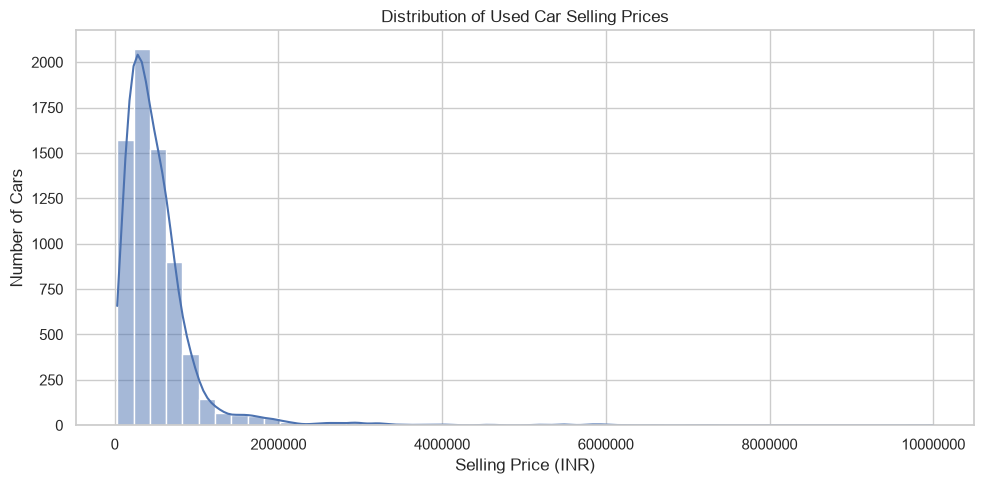

In [138]:
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import StrMethodFormatter

plt.figure(figsize=(10, 5))

ax = sns.histplot(
    df_clean["selling_price"],
    bins=50,
    kde=True
)

ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))

plt.title("Distribution of Used Car Selling Prices")
plt.xlabel("Selling Price (INR)")
plt.ylabel("Number of Cars")

plt.tight_layout()
plt.show()

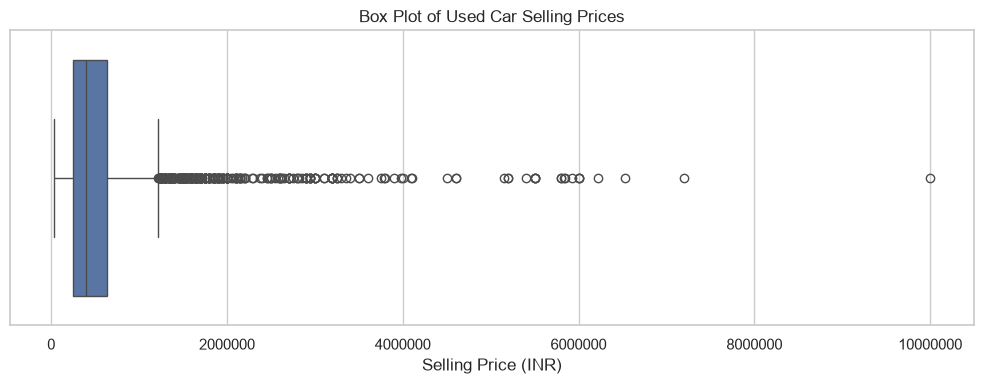

In [71]:
plt.figure(figsize=(10, 4))

ax = sns.boxplot(x=df_clean["selling_price"])

ax.xaxis.set_major_formatter(StrMethodFormatter('{x:.0f}'))

plt.title("Box Plot of Used Car Selling Prices")
plt.xlabel("Selling Price (INR)")

plt.tight_layout()
plt.show()

### **Interpretation of Selling Price Distribution**

* The histogram indicates that the selling price distribution is positively skewed, with most vehicles concentrated in the lower and mid-price ranges. A relatively small number of expensive vehicles extend the distribution towards higher prices.
* The box plot further highlights several observations beyond the upper whisker, indicating the presence of potential statistical outliers. The median selling price is ₹4,00,000, while the middle 50% of vehicle prices range approximately from ₹2,50,000 to ₹6,34,000.
* These high-priced observations may represent premium and luxury vehicles rather than incorrect data. Therefore, they are retained for further analysis instead of being removed solely based on statistical outlier detection.


### **Analyse vehicle manufacturing year**

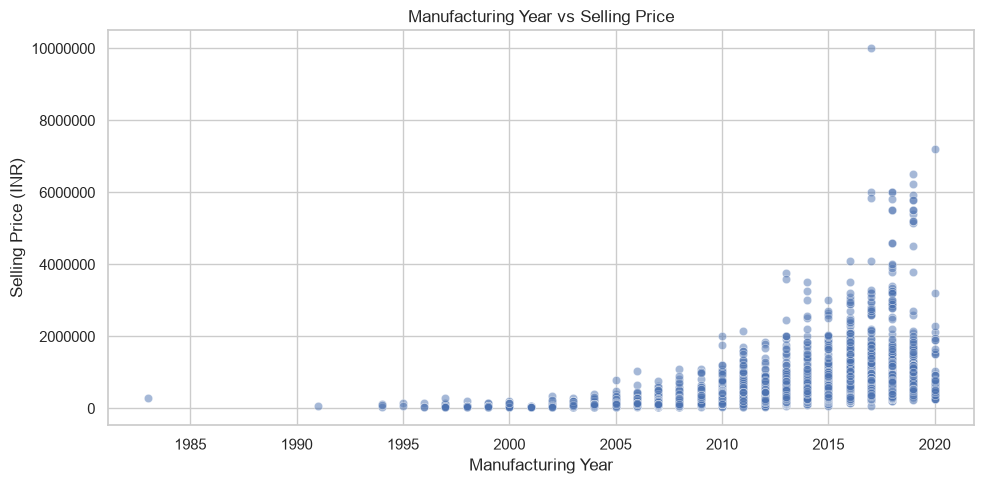

In [140]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df_clean,
    x="year",
    y="selling_price",
    alpha=0.5
)

plt.title("Manufacturing Year vs Selling Price")
plt.xlabel("Manufacturing Year")
plt.ylabel("Selling Price (INR)")

plt.ticklabel_format(
    style="plain",
    axis="y"
)

plt.tight_layout()
plt.show()

### **Interpretation of Manufacturing Year vs Selling Price**

* The analysis examines the relationship between a vehicle's manufacturing year and its selling price.
* The results indicate a general upward trend in selling prices for newer vehicles. Older vehicles, particularly those manufactured before 2010, generally have lower average selling prices. From 2010 onwards, selling prices show a considerable increase.
* The highest average selling price is observed for vehicles manufactured in 2019, at approximately ₹9,49,669. However, vehicles manufactured in 2020 show a slightly lower average and median selling price.
* The number of observations varies across manufacturing years, which should be considered when interpreting the results. Overall, manufacturing year appears to be an important feature influencing used-car selling prices.


### **Kilometres driven vs Selling price**

In [73]:
km_quantile_analysis = df_clean.copy()

km_quantile_analysis["km_group"] = pd.qcut(
    km_quantile_analysis["km_driven"],
    q=5,
    duplicates="drop"
)

km_analysis = km_quantile_analysis.groupby(
    "km_group",
    observed=True
)["selling_price"].agg(
    ["count", "mean", "median"]
).round(2)

display(km_analysis)

,count,mean,median
km_group,,,
"(0.999, 31000.0]",1390,741743.13,564000.0
"(31000.0, 56345.0]",1380,576142.42,459999.0
"(56345.0, 80000.0]",1700,456762.11,375000.0
"(80000.0, 110000.0]",1222,400886.67,330000.0
"(110000.0, 1500000.0]",1233,397070.66,325000.0


### **Interpretation of Kilometres Driven vs Selling Price**

* This analysis investigates the relationship between the distance travelled by a vehicle and its selling price. Quantile-based grouping was applied to divide the vehicles into five groups containing approximately equal numbers of observations.
* The results indicate a general negative relationship between kilometres driven and selling price. Vehicles driven up to 31,000 km have the highest average selling price of approximately ₹7,41,743, whereas vehicles driven above 1,10,000 km have the lowest average selling price of approximately ₹3,97,071.
* A similar downward trend is observed in median selling prices across the five groups. These findings suggest that vehicles with lower usage generally have higher resale values.
* Overall, kilometres driven appears to be an important feature associated with used-car selling prices. However, other factors, including manufacturing year, manufacturer, engine specifications, and vehicle condition, may also influence the final price.

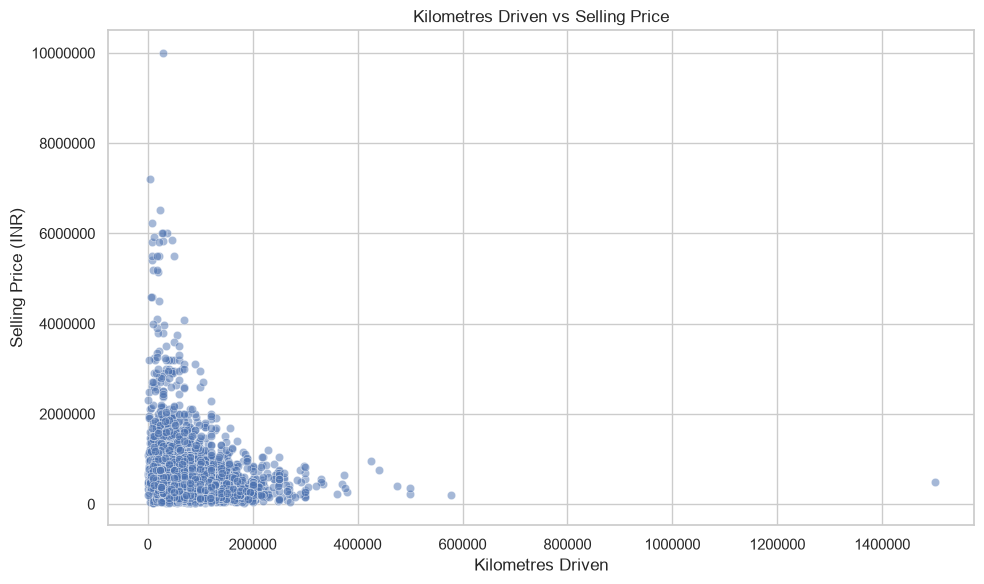

In [142]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x="km_driven",
    y="selling_price",
    alpha=0.5
)

plt.title("Kilometres Driven vs Selling Price")
plt.xlabel("Kilometres Driven")
plt.ylabel("Selling Price (INR)")

plt.ticklabel_format(style="plain", axis="both")

plt.tight_layout()
plt.show()

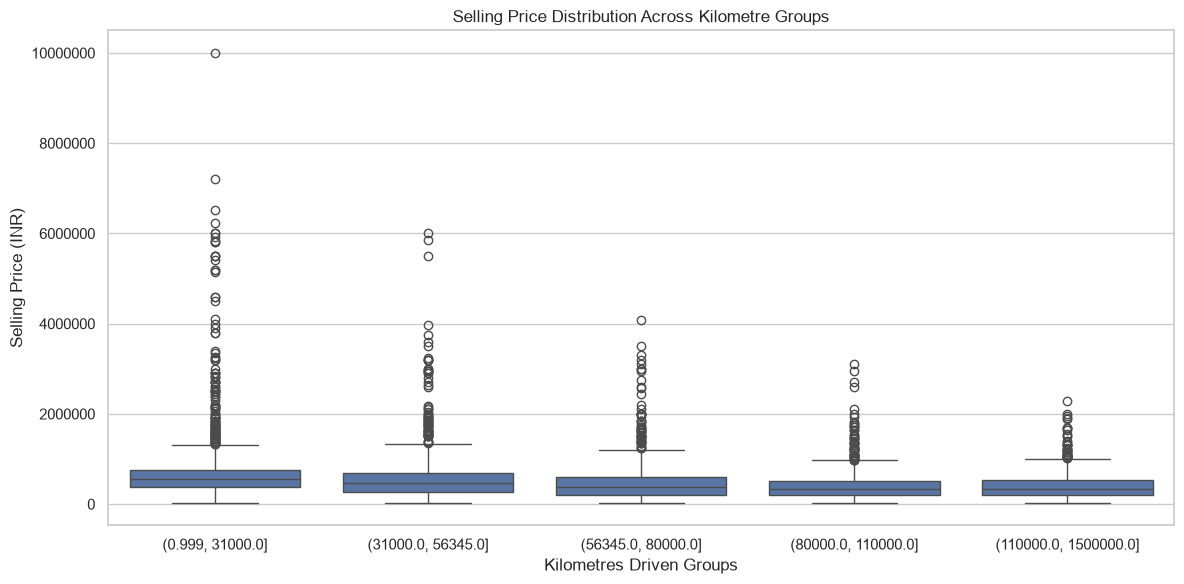

In [75]:
plt.figure(figsize=(12, 6))

sns.boxplot(
    data=km_quantile_analysis,
    x="km_group",
    y="selling_price"
)

plt.title("Selling Price Distribution Across Kilometre Groups")
plt.xlabel("Kilometres Driven Groups")
plt.ylabel("Selling Price (INR)")

plt.ticklabel_format(style="plain", axis="y")
plt.xticks()

plt.tight_layout()
plt.show()

### **Visual Analysis of Kilometres Driven vs Selling Price**

* A scatter plot and box plot are used to visually examine the relationship between kilometres driven and used-car selling prices.
* The scatter plot illustrates the distribution of vehicle prices across different kilometre readings. The box plot compares the selling price distributions across five quantile-based kilometre groups.
* The visual analysis supports the numerical findings, indicating that vehicles with lower kilometres driven generally have higher selling prices. However, considerable variation exists within each group, suggesting that other vehicle characteristics also influence resale value.


### **Fuel type vs Selling price**

In [76]:
fuel_analysis = df_clean.groupby("fuel")["selling_price"].agg(
    ["count", "mean", "median"]
).sort_values(by="mean", ascending=False).round(2)

display(fuel_analysis)

,count,mean,median
fuel,,,
Diesel,3755,639727.77,520000.0
Petrol,3076,375632.30,310000.0
CNG,56,300499.95,320000.0
LPG,38,200421.05,195500.0


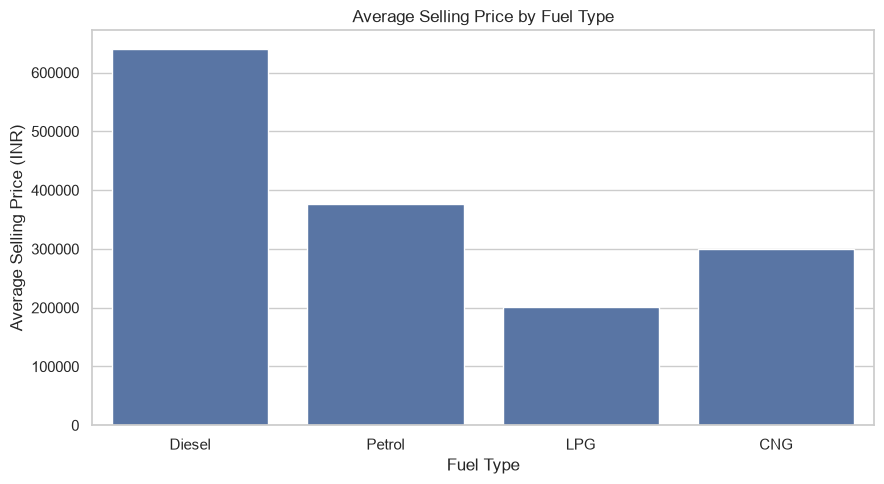

In [144]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="fuel",
    y="selling_price",
    estimator="mean",
    errorbar=None
)

plt.title("Average Selling Price by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Selling Price (INR)")

plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

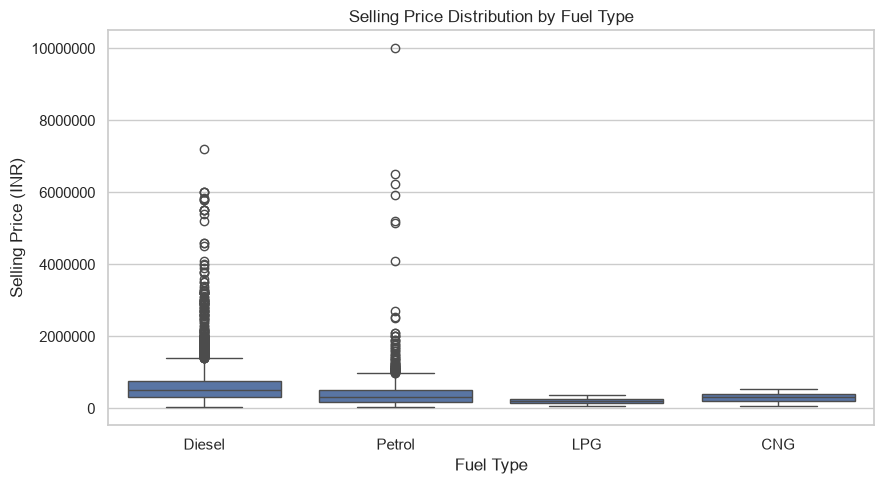

In [78]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="fuel",
    y="selling_price"
)

plt.title("Selling Price Distribution by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Selling Price (INR)")

plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

### **Interpretation of Fuel Type vs Selling Price**

* This analysis examines the relationship between vehicle fuel type and selling price.
* The results indicate that diesel vehicles have the highest average selling price of approximately ₹6,39,728, followed by petrol vehicles at ₹3,75,632. CNG vehicles have an average selling price of approximately ₹3,00,500, while LPG vehicles have the lowest average selling price of approximately ₹2,00,421.
* Diesel and petrol vehicles represent the majority of observations in the dataset, whereas CNG and LPG vehicles have considerably fewer records.
* Overall, fuel type appears to be an important feature associated with used-car selling prices. However, differences in vehicle models, manufacturing years and specifications may also contribute to the observed price variations.


### **Seller Type vs Selling Price**

In [79]:
seller_analysis = df_clean.groupby(
    "seller_type"
)["selling_price"].agg(
    ["count", "mean", "median"]
).sort_values(
    by="mean",
    ascending=False
).round(2)

display(seller_analysis)

,count,mean,median
seller_type,,,
Dealer,681,926722.42,620000.0
Trustmark Dealer,27,718111.11,650000.0
Individual,6217,471542.51,390000.0


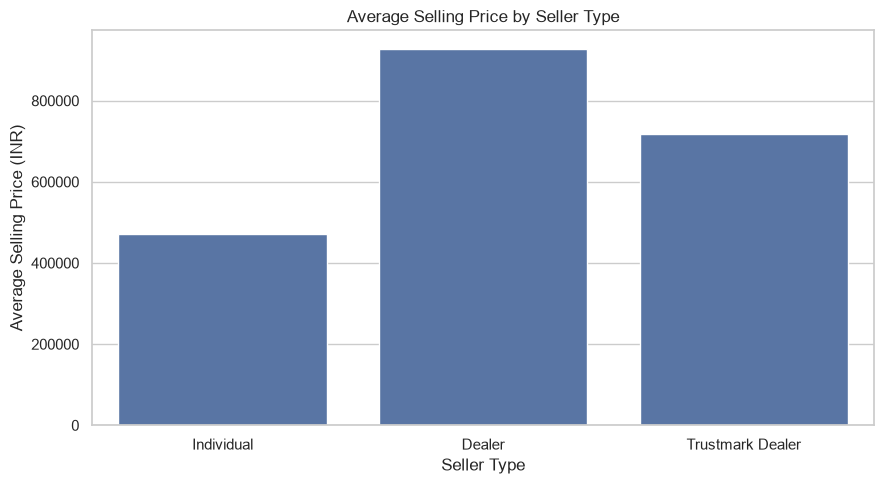

In [146]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_clean,
    x="seller_type",
    y="selling_price",
    estimator="mean",
    errorbar=None
)

plt.title("Average Selling Price by Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Average Selling Price (INR)")

plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

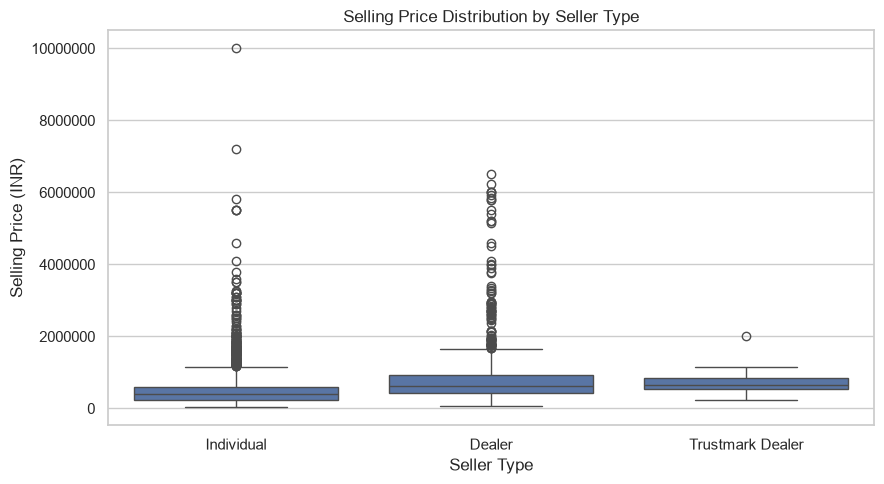

In [81]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df_clean,
    x="seller_type",
    y="selling_price"
)

plt.title("Selling Price Distribution by Seller Type")
plt.xlabel("Seller Type")
plt.ylabel("Selling Price (INR)")

plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

### **Interpretation of Seller Type vs Selling Price**

* The relationship between seller type and selling price was analysed to understand how vehicle prices vary across different seller categories.
* The analysis shows that vehicles sold by dealers have the highest average selling price of ₹9,26,722.42, followed by Trustmark Dealers at ₹7,18,111.11. Vehicles sold by individual sellers have the lowest average selling price of ₹4,71,542.51.
* The median selling price is highest for Trustmark Dealers at ₹6,50,000, followed by Dealers at ₹6,20,000 and Individual Sellers at ₹3,90,000.
* These findings suggest that vehicles listed by dealers and Trustmark Dealers tend to have higher selling prices than those listed by individual sellers. However, the Trustmark Dealer category contains only 27 records, so its results should be interpreted cautiously.


### **Transmission Type vs Selling Price**

In [82]:
transmission_analysis = df_clean.groupby("transmission")["selling_price"].agg(
    ["count", "mean", "median"]
).sort_values(by="mean", ascending=False).round(2)

display(transmission_analysis)

,count,mean,median
transmission,,,
Automatic,584,1309712.30,850000.0
Manual,6341,444282.41,385000.0


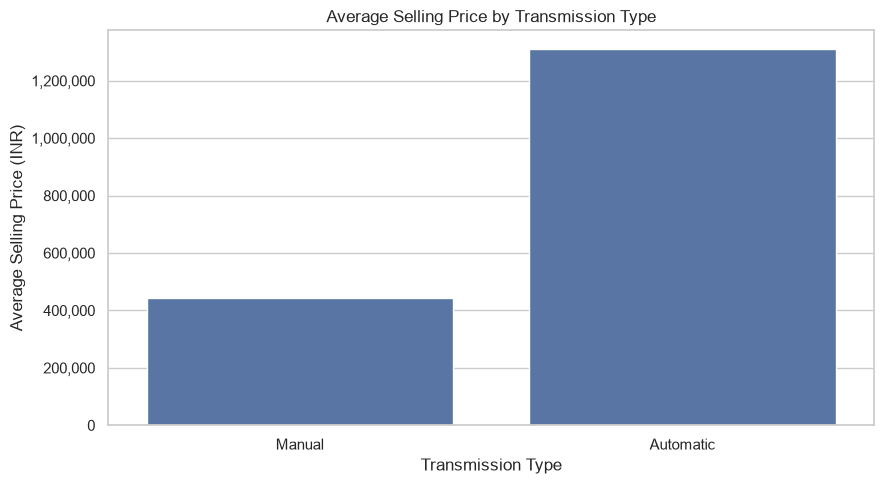

In [148]:
plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=df_clean,
    x="transmission",
    y="selling_price",
    estimator="mean",
    errorbar=None
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

plt.title("Average Selling Price by Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Average Selling Price (INR)")

plt.tight_layout()
plt.show()

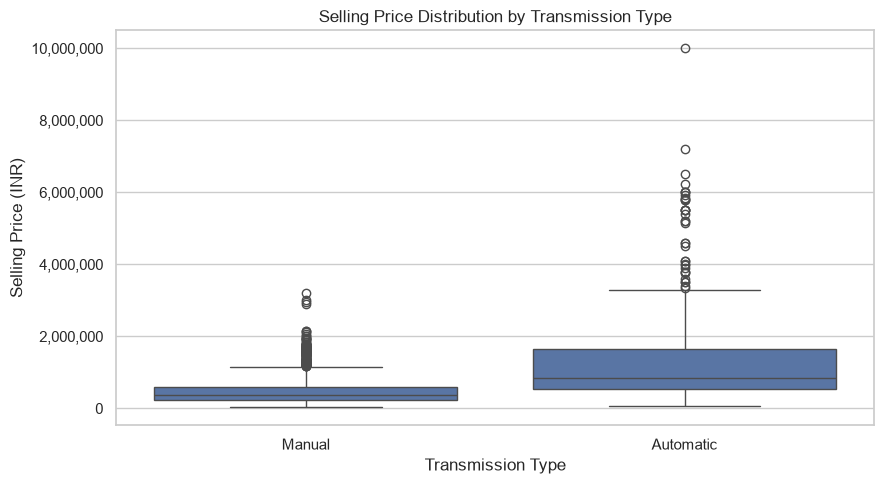

In [84]:
plt.figure(figsize=(9, 5))

ax = sns.boxplot(
    data=df_clean,
    x="transmission",
    y="selling_price"
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

plt.title("Selling Price Distribution by Transmission Type")
plt.xlabel("Transmission Type")
plt.ylabel("Selling Price (INR)")

plt.tight_layout()
plt.show()

### **Interpretation of Transmission Type vs Selling Price**

* The relationship between transmission type and selling price was analysed to understand the price differences between automatic and manual vehicles.
* The analysis shows that automatic vehicles have an average selling price of ₹13,09,712.30 and a median selling price of ₹8,50,000. In comparison, manual vehicles have an average selling price of ₹4,44,282.41 and a median selling price of ₹3,85,000.
* The dataset contains 6,341 manual vehicles and 584 automatic vehicles, indicating that manual transmission vehicles are significantly more common.
* The results suggest that automatic vehicles tend to have higher selling prices than manual vehicles. However, other factors, such as vehicle model, manufacturing year and engine specifications, may also contribute to this difference.


### **Owner Type vs Selling Price**

In [85]:
owner_analysis = df_clean.groupby("owner")["selling_price"].agg(
    ["count", "mean", "median"]
).sort_values(by="mean", ascending=False).round(2)

display(owner_analysis)

,count,mean,median
owner,,,
Test Drive Car,5,4403800.00,5923000.0
First Owner,4242,615404.40,500000.0
Second Owner,1973,385613.92,305000.0
Third Owner,536,281250.95,222500.0
Fourth & Above Owner,169,224470.37,170000.0


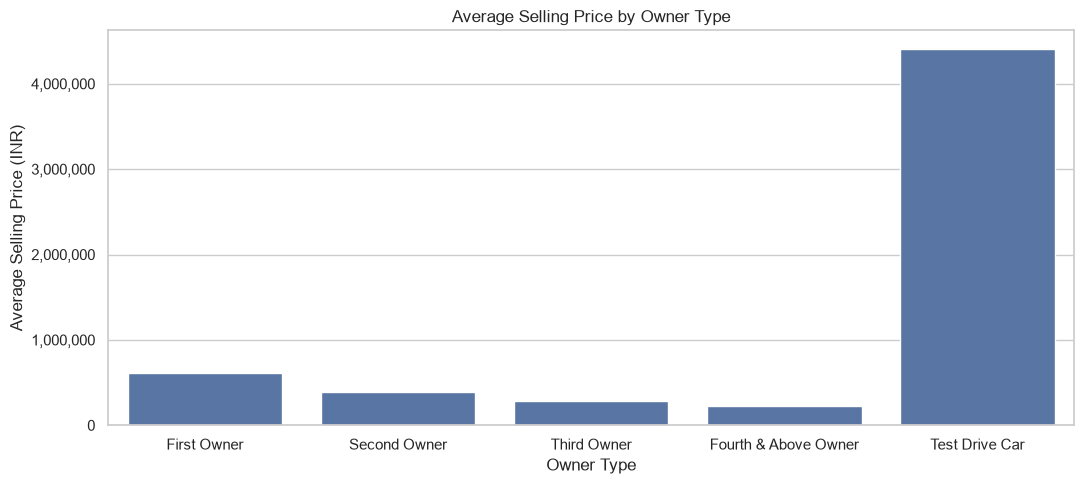

In [150]:
plt.figure(figsize=(11, 5))

ax = sns.barplot(
    data=df_clean,
    x="owner",
    y="selling_price",
    estimator="mean",
    errorbar=None
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

plt.title("Average Selling Price by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Average Selling Price (INR)")

plt.tight_layout()
plt.show()

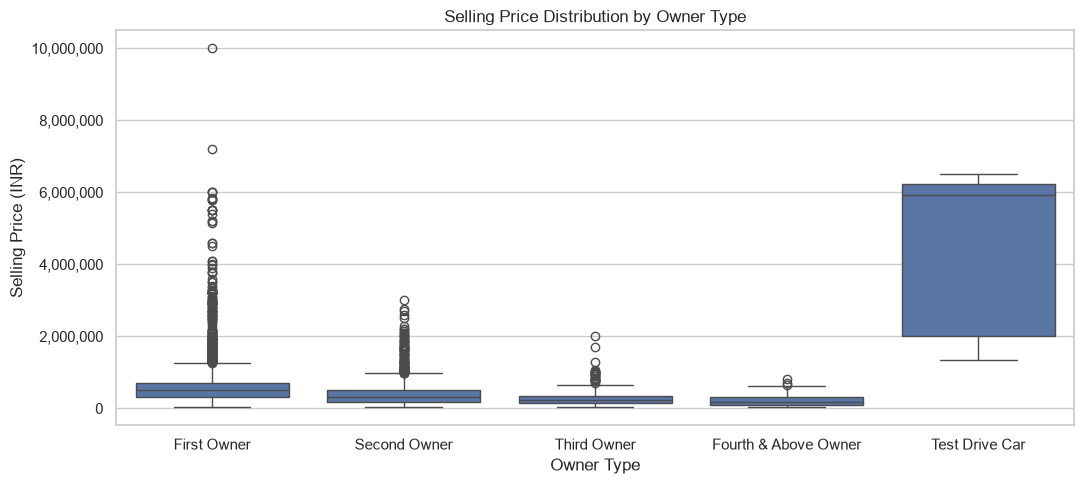

In [87]:
plt.figure(figsize=(11, 5))

ax = sns.boxplot(
    data=df_clean,
    x="owner",
    y="selling_price"
)

ax.yaxis.set_major_formatter(
    StrMethodFormatter('{x:,.0f}')
)

plt.title("Selling Price Distribution by Owner Type")
plt.xlabel("Owner Type")
plt.ylabel("Selling Price (INR)")
plt.tight_layout()
plt.show()

### **Interpretation of Owner Type vs Selling Price**

* The relationship between ownership history and selling price was analysed to understand how the number of previous owners influences the resale value of vehicles.
* The analysis shows that first-owner vehicles have an average selling price of ₹6,15,404.40, while second-owner vehicles have an average of ₹3,85,613.92. The average selling price further decreases to ₹2,81,250.95 for third-owner vehicles and ₹2,24,470.37 for vehicles with fourth or more previous owners.
* Test Drive Cars have the highest average selling price of ₹44,03,800. However, this category contains only five records, so the result should be interpreted cautiously.
* Overall, the findings indicate that vehicles with fewer previous owners generally have higher selling prices. This suggests that ownership history is an important feature to consider when predicting used car prices.


### **Correlation Analysis**

* Correlation analysis is performed to identify the relationships between numerical features in the dataset. It helps determine which features have stronger positive or negative relationships with the target variable, selling price.
* The correlation matrix is used to examine relationships between manufacturing year, kilometres driven, mileage, engine capacity, maximum power, torque, seats and selling price.
* A heatmap is also generated to visually represent the correlation coefficients and identify potentially useful features for the machine learning model.


In [88]:
numerical_df = df_clean.select_dtypes(include=["number"])

correlation_matrix = numerical_df.corr()

display(correlation_matrix.round(2))

,year,selling_price,km_driven,mileage,engine,max_power,torque,seats
year,1.00,0.43,-0.42,0.37,-0.02,0.16,0.15,0.02
selling_price,0.43,1.00,-0.19,-0.11,0.44,0.69,0.63,0.16
km_driven,-0.42,-0.19,1.00,-0.23,0.29,0.05,0.18,0.24
mileage,0.37,-0.11,-0.23,1.00,-0.59,-0.39,-0.25,-0.48
engine,-0.02,0.44,0.29,-0.59,1.00,0.68,0.75,0.66
max_power,0.16,0.69,0.05,-0.39,0.68,1.00,0.84,0.26
torque,0.15,0.63,0.18,-0.25,0.75,0.84,1.00,0.40
seats,0.02,0.16,0.24,-0.48,0.66,0.26,0.40,1.00


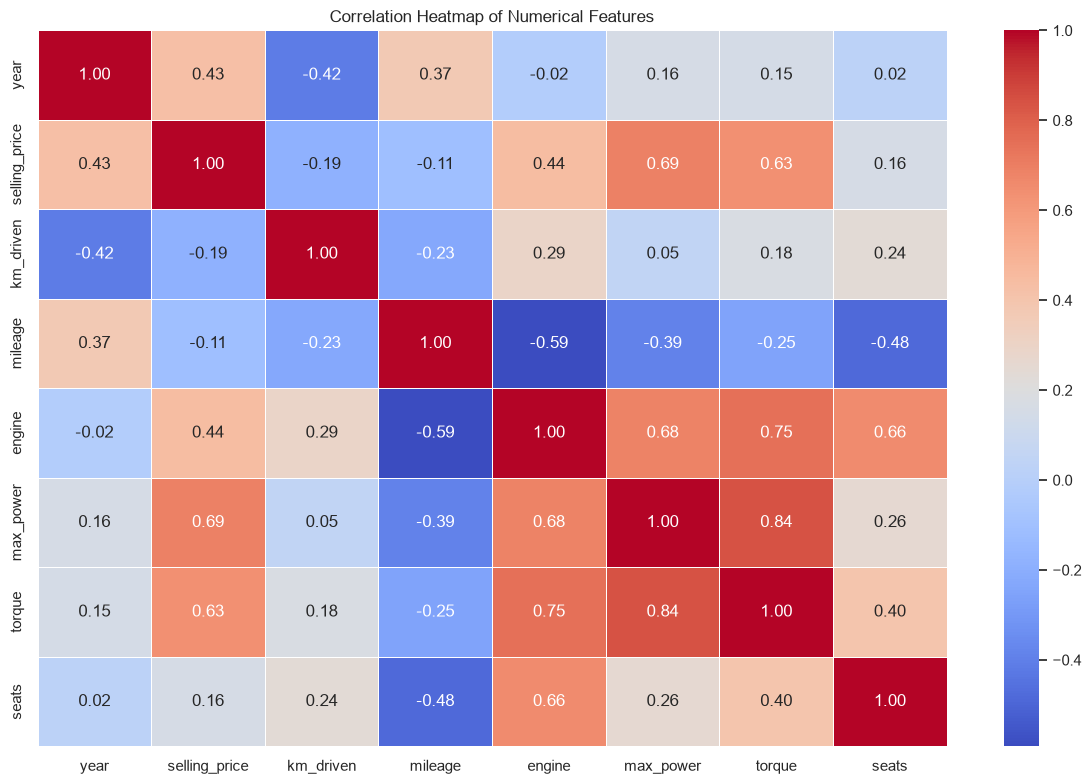

In [152]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

### **Interpretation of Correlation Analysis**

* Correlation analysis was performed to examine the relationships between numerical features and the target variable, selling price.
* The results indicate that torque has the strongest positive correlation with selling price, with a coefficient of 0.69, followed by maximum power at 0.63. Engine capacity and manufacturing year also show moderate positive correlations of 0.44 and 0.43, respectively.
* Kilometres driven has a weak negative correlation of -0.19, while mileage has a weak negative correlation of -0.11. Seats show a weak positive correlation of 0.16.
* The analysis also identifies strong relationships between certain independent features, particularly maximum power and torque, which have a correlation of 0.84.
* Overall, torque, maximum power, engine capacity and manufacturing year appear to have useful linear relationships with selling price. These findings will help guide feature selection and model development. However, correlation alone does not establish causation or determine the predictive importance of a feature.


### **Visualise feature relationships**

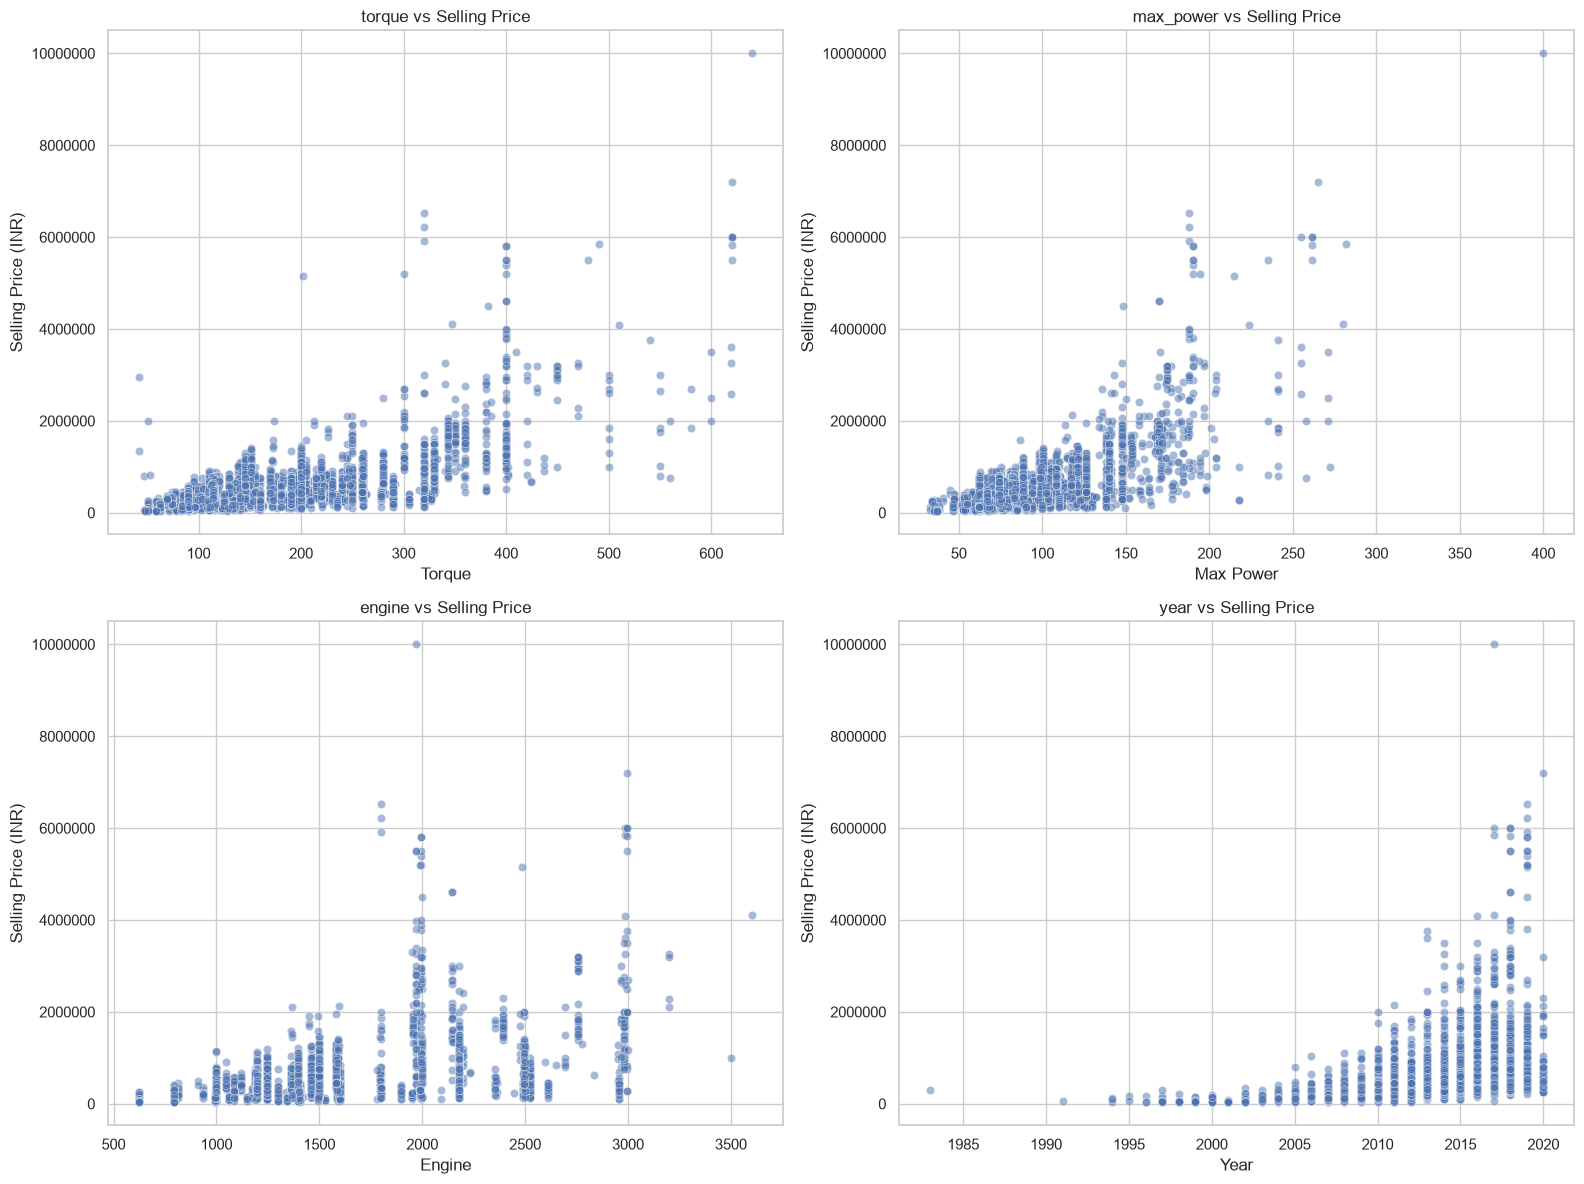

In [154]:
features = ["torque", "max_power", "engine", "year"]

plt.figure(figsize=(16, 12))

for i, feature in enumerate(features, 1):
    plt.subplot(2, 2, i)

    sns.scatterplot(
        data=df_clean,
        x=feature,
        y="selling_price",
        alpha=0.5
    )

    plt.title(f"{feature} vs Selling Price")
    plt.xlabel(feature.replace("_", " ").title())
    plt.ylabel("Selling Price (INR)")
    plt.ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.show()

### **Interpretation of Numerical Feature Relationship Analysis**

* Scatter plots were generated to examine the relationships between selected numerical features and selling price.
* The visual analysis focuses on torque, maximum power, engine capacity and manufacturing year. These features were selected because they showed relatively stronger positive correlations with selling price.
* The plots help examine the distribution of vehicle prices, identify potential outliers and understand whether the relationships between the selected features and selling price follow a linear pattern.


### **Exploratory Data Analysis Summary**

Exploratory Data Analysis was performed on the CarDekho used car dataset to understand the characteristics of the data and identify factors associated with vehicle selling prices.

The original dataset contained 8,128 records and 13 columns. After removing 1,202 duplicate records and excluding one vehicle record with a potentially erroneous kilometre reading, the dataset contains 6,925 records and 15 columns following feature engineering.

The major findings are:

1. **Selling Price:** The selling price distribution is positively skewed, with an average price of approximately ₹5.17 lakh and a median of ₹4 lakh.
2. **Manufacturing Year:** Newer vehicles generally have higher selling prices than older vehicles.
3. **Kilometres Driven:** Vehicles with higher kilometres driven generally tend to have lower selling prices.
4. **Fuel Type:** Diesel vehicles have a higher average selling price than petrol, CNG and LPG vehicles in this dataset.
5. **Seller Type:** Dealer-listed vehicles have a higher average selling price than individually listed vehicles.
6. **Transmission:** Automatic vehicles have considerably higher average selling prices than manual vehicles.
7. **Ownership:** Vehicles with fewer previous owners generally have higher selling prices.
8. **Correlation Analysis:** Torque, maximum power, engine capacity and manufacturing year show relatively stronger positive correlations with selling price.

The analysis also identified missing values in certain vehicle specifications, including mileage, engine, maximum power, torque and seats. These missing values will be handled during the preprocessing stage.

Overall, the EDA helped identify important patterns, understand data quality issues and determine the features that may contribute to used car price prediction.


In [91]:
print("Final Dataset Shape:", df_clean.shape)

print("\nMissing Values:")
display(
    df_clean.isnull().sum().to_frame(name="Missing Count")
)

print("\nData Types:")
display(df_clean.dtypes.to_frame(name="Data Type"))

print("\nFirst Five Records:")
display(df_clean.head())

Final Dataset Shape: (6925, 15)

Missing Values:


,Missing Count
name,0
year,0
selling_price,0
km_driven,0
fuel,0
seller_type,0
transmission,0
owner,0
mileage,223
engine,208



Data Types:


,Data Type
name,str
year,int64
selling_price,int64
km_driven,int64
fuel,str
seller_type,str
transmission,str
owner,str
mileage,float64
engine,float64



First Five Records:


,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,manufacturer,mileage_unit
0,Maruti Swift Dzire VDI,2014,450000,145500,Diesel,Individual,Manual,First Owner,23.40,1248.0,74.00,190.000000,5.0,Maruti,kmpl
1,Skoda Rapid 1.5 TDI Ambition,2014,370000,120000,Diesel,Individual,Manual,Second Owner,21.14,1498.0,103.52,250.000000,5.0,Skoda,kmpl
2,Honda City 2017-2020 EXi,2006,158000,140000,Petrol,Individual,Manual,Third Owner,17.70,1497.0,78.00,124.544455,5.0,Honda,kmpl
3,Hyundai i20 Sportz Diesel,2010,225000,127000,Diesel,Individual,Manual,First Owner,23.00,1396.0,90.00,219.668960,5.0,Hyundai,kmpl
4,Maruti Swift VXI BSIII,2007,130000,120000,Petrol,Individual,Manual,First Owner,16.10,1298.0,88.20,112.776475,5.0,Maruti,kmpl


## **8. Feature and Target Selection**

* The cleaned dataset was divided into input features and a target variable to prepare it for machine learning.
* The target variable is `selling_price`, which represents the selling price of a used vehicle. The remaining relevant columns are used as input features to predict the vehicle's selling price.
* The `name` column was excluded from the initial model because it contains a large number of unique vehicle names. Instead, the `manufacturer` column was retained to represent the vehicle brand.


In [92]:
# Separate input features and target variable

X = df_clean.drop(
    columns=["selling_price", "name"]
)

y = df_clean["selling_price"]

print("Feature Matrix Shape:", X.shape)
print("Target Variable Shape:", y.shape)

print("\nInput Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(y.name)

Feature Matrix Shape: (6925, 13)
Target Variable Shape: (6925,)

Input Features:
['year', 'km_driven', 'fuel', 'seller_type', 'transmission', 'owner', 'mileage', 'engine', 'max_power', 'torque', 'seats', 'manufacturer', 'mileage_unit']

Target Variable:
selling_price


## **9. Saving the Processed Dataset**

After completing data cleaning, handling duplicate records, correcting invalid values and performing feature engineering, the cleaned dataset was saved for further machine learning tasks.

The processed dataset contains 6,925 records and 15 columns. Missing values in vehicle specifications were retained because they will be handled through an imputation pipeline during model development.

The original dataset remains unchanged in the `data/raw` directory, while the cleaned dataset is stored separately in the `data/processed` directory.


In [93]:
from pathlib import Path

# Define processed data directory
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

# Create directory if it does not exist
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# Define output file path
PROCESSED_PATH = PROCESSED_DIR / "used_car_price_processed.csv"

# Save cleaned dataset
df_clean.to_csv(PROCESSED_PATH, index=False)

print("Processed dataset saved successfully!")
print("File location:", PROCESSED_PATH)
print("Dataset shape:", df_clean.shape)

Processed dataset saved successfully!
File location: c:\Used-Car-Price-Prediction\data\processed\used_car_price_processed.csv
Dataset shape: (6925, 15)


In [94]:
processed_df = pd.read_csv(PROCESSED_PATH)

print("Loaded processed dataset:", processed_df.shape)
print("Missing values:", processed_df.isnull().sum().sum())
print("Duplicate rows:", processed_df.duplicated().sum())

Loaded processed dataset: (6925, 15)
Missing values: 1278
Duplicate rows: 0


In [95]:
print("Missing values in original cleaned DataFrame:")
display(df_clean.isnull().sum())

print("\nMissing values in reloaded CSV:")
display(processed_df.isnull().sum())

print("\nTotal missing values before saving:", df_clean.isnull().sum().sum())
print("Total missing values after loading:", processed_df.isnull().sum().sum())

Missing values in original cleaned DataFrame:


name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          223
engine           208
max_power        209
torque           222
seats            208
manufacturer       0
mileage_unit     208
dtype: int64


Missing values in reloaded CSV:


name               0
year               0
selling_price      0
km_driven          0
fuel               0
seller_type        0
transmission       0
owner              0
mileage          223
engine           208
max_power        209
torque           222
seats            208
manufacturer       0
mileage_unit     208
dtype: int64


Total missing values before saving: 1278
Total missing values after loading: 1278


In [96]:
print("Empty strings before saving:")
print((df_clean == "").sum())

print("\nEmpty strings after loading:")
print((processed_df == "").sum())

Empty strings before saving:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
manufacturer     0
mileage_unit     0
dtype: int64

Empty strings after loading:
name             0
year             0
selling_price    0
km_driven        0
fuel             0
seller_type      0
transmission     0
owner            0
mileage          0
engine           0
max_power        0
torque           0
seats            0
manufacturer     0
mileage_unit     0
dtype: int64


## **10. Train-Test Split**

* The processed dataset was divided into training and testing subsets using an 80:20 ratio. The training subset is used to train the machine learning models, while the testing subset is reserved for evaluating their predictive performance on unseen data.
* A fixed random state of 42 was used to ensure reproducibility. This separation also helps prevent data leakage during model development.


In [97]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (5540, 13)
Testing Features: (1385, 13)
Training Target: (5540,)
Testing Target: (1385,)


## **11. Data Preprocessing**

* Data preprocessing is an important step before training machine learning models. The dataset contains both numerical and categorical features, along with missing values in certain vehicle specifications.
* To prepare the data for machine learning, numerical features will undergo median imputation and standardization, while categorical features will undergo most-frequent-value imputation and one-hot encoding.
* A Scikit-learn preprocessing pipeline will be implemented to ensure consistent transformations and prevent data leakage. All preprocessing operations will be fitted using the training dataset and subsequently applied to the testing dataset.


In [98]:
# Identify numerical and categorical features

numerical_features = [
    "year",
    "km_driven",
    "mileage",
    "engine",
    "max_power",
    "torque",
    "seats"
]

categorical_features = [
    "fuel",
    "seller_type",
    "transmission",
    "owner",
    "manufacturer",
    "mileage_unit"
]

print("Numerical Features:", numerical_features)
print("\nNumber of Numerical Features:", len(numerical_features))

print("\nCategorical Features:", categorical_features)
print("\nNumber of Categorical Features:", len(categorical_features))

Numerical Features: ['year', 'km_driven', 'mileage', 'engine', 'max_power', 'torque', 'seats']

Number of Numerical Features: 7

Categorical Features: ['fuel', 'seller_type', 'transmission', 'owner', 'manufacturer', 'mileage_unit']

Number of Categorical Features: 6


In [99]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Numerical preprocessing pipeline
numerical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]
)

# Categorical preprocessing pipeline
categorical_transformer = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]
)

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numerical_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [100]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the fitted preprocessing pipeline
X_test_processed = preprocessor.transform(X_test)

print("Training data after preprocessing:", X_train_processed.shape)
print("Testing data after preprocessing:", X_test_processed.shape)

Training data after preprocessing: (5540, 53)
Testing data after preprocessing: (1385, 53)


## **12. Training Our Regression Model**

### **Linear Regression**

* Linear Regression is used as the baseline machine learning algorithm for predicting used car selling prices. It attempts to identify the relationship between vehicle characteristics and their selling prices.
* The model uses the preprocessed numerical features to estimate the selling price of a vehicle. Its performance will serve as a reference point for comparison with more advanced regression algorithms.


In [101]:
from sklearn.linear_model import LinearRegression

# Initialize Linear Regression
linear_model = LinearRegression()

# Train the model
linear_model.fit(X_train_processed, y_train)

print("Linear Regression model trained successfully!")

Linear Regression model trained successfully!


In [102]:
# Predict selling prices on test data
y_pred_linear = linear_model.predict(X_test_processed)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred_linear[:10])

First 10 Actual Prices:
[ 250000 2600000  800000  475000  350000  400000  148000  150000  600000
  625000]

First 10 Predicted Prices:
[ 412443.6982238  2505048.63684011  655014.15087972  585056.37326673
  687780.39863424  348954.43918724  169743.8254127   -52448.4040831
  680639.50108202  581886.83257158]


#### **Model Evaluation Of Linear Regression Model**

* The Linear Regression model was evaluated using three performance metrics: Mean Absolute Error (MAE), Root Mean Squared Error (RMSE) and the R-squared (R²) score.
* MAE measures the average absolute difference between actual and predicted selling prices. RMSE gives greater importance to larger prediction errors, while the R² score indicates how well the model explains variations in vehicle selling prices.
* These metrics provide a quantitative assessment of model performance and will be used to compare different regression algorithms.


In [103]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred_linear)

rmse = np.sqrt(mean_squared_error(y_test, y_pred_linear))

r2 = r2_score(y_test, y_pred_linear)

print("Linear Regression Model Evaluation")
print("-----------------------------------")
print(f"MAE  : ₹{mae:,.2f}")
print(f"RMSE : ₹{rmse:,.2f}")
print(f"R²   : {r2:.4f}")

Linear Regression Model Evaluation
-----------------------------------
MAE  : ₹134,109.10
RMSE : ₹263,647.10
R²   : 0.7152


#### **Linear Regression Results**

* The Linear Regression model achieved an R² score of 0.7152, indicating that it explains approximately 71.52% of the variation in used car selling prices on the test dataset.
* The model recorded a Mean Absolute Error (MAE) of ₹1,34,109.10 and a Root Mean Squared Error (RMSE) of ₹2,63,647.10.
* The difference between MAE and RMSE indicates that some predictions contain relatively large errors. Although Linear Regression provides a reasonable baseline, its predictive performance can potentially be improved using more advanced regression algorithms.


### **Decision Tree Regression**

* Decision Tree Regression is a supervised machine learning algorithm that predicts continuous numerical values by learning decision rules from the training data.
* The algorithm divides the dataset into smaller groups based on feature conditions and generates predictions using the resulting tree structure.
* It can capture nonlinear relationships between vehicle characteristics and selling prices, making it useful for comparison with the Linear Regression baseline.


In [104]:
from sklearn.tree import DecisionTreeRegressor

# Initialize Decision Tree Regressor
decision_tree_model = DecisionTreeRegressor(
    random_state=42
)

# Train the model
decision_tree_model.fit(X_train_processed, y_train)

print("Decision Tree Regression model trained successfully!")

Decision Tree Regression model trained successfully!


In [105]:
# Predict selling prices
y_pred_tree = decision_tree_model.predict(X_test_processed)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred_tree[:10])

First 10 Actual Prices:
[ 250000 2600000  800000  475000  350000  400000  148000  150000  600000
  625000]

First 10 Predicted Prices:
[ 375000.         2700000.          711666.66666667  480000.
  450000.          360000.          150000.           80000.
  450000.          625000.        ]


In [106]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Calculate evaluation metrics
mae_tree = mean_absolute_error(y_test, y_pred_tree)

rmse_tree = np.sqrt(mean_squared_error(y_test, y_pred_tree))

r2_tree = r2_score(y_test, y_pred_tree)

print("Decision Tree Model Evaluation")
print("-----------------------------------")
print(f"MAE  : ₹{mae_tree:,.2f}")
print(f"RMSE : ₹{rmse_tree:,.2f}")
print(f"R²   : {r2_tree:.4f}")

Decision Tree Model Evaluation
-----------------------------------
MAE  : ₹96,463.49
RMSE : ₹196,234.42
R²   : 0.8422


In [107]:
model_comparison = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree"],
    "MAE": [mae, mae_tree],
    "RMSE": [rmse, rmse_tree],
    "R2 Score": [r2, r2_tree]
})

display(model_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,134109.0996,263647.0962,0.7152
1,Decision Tree,96463.4922,196234.4156,0.8422


#### **Decision Tree Results and Model Comparison**

* The Decision Tree Regression model achieved an R² score of 0.8422, explaining approximately 84.22% of the variation in used car selling prices on the test dataset.
* The model recorded an MAE of ₹96,463.49 and an RMSE of ₹196,234.42.
* Compared with Linear Regression, the Decision Tree model demonstrated better performance across all three evaluation metrics. Its lower MAE and RMSE indicate improved prediction accuracy, while its higher R² score suggests that it captures nonlinear relationships between vehicle characteristics and selling prices more effectively.
* These results indicate that Decision Tree Regression is a stronger model than the Linear Regression baseline for this dataset. However, further evaluation is required to check for overfitting and identify a more reliable model.


### **Random Forest Regression**

* Random Forest Regression is an ensemble learning algorithm that combines predictions from multiple decision trees to produce a final prediction.
* Each tree is trained using a different sample of the training data and considers randomly selected subsets of features when making decisions. The final prediction is obtained by averaging the predictions of individual trees.
* This approach helps reduce the variance associated with individual decision trees and can improve prediction accuracy and model generalization.


In [108]:
from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest Regressor
random_forest_model = RandomForestRegressor(
    n_estimators=200,
    random_state=42,
    n_jobs=-1
)

# Train the model
random_forest_model.fit(X_train_processed, y_train)

print("Random Forest Regression model trained successfully!")

Random Forest Regression model trained successfully!


In [109]:
# Predict selling prices
y_pred_rf = random_forest_model.predict(X_test_processed)

print("First 10 Actual Prices:")
print(y_test.head(10).values)

print("\nFirst 10 Predicted Prices:")
print(y_pred_rf[:10])

First 10 Actual Prices:
[ 250000 2600000  800000  475000  350000  400000  148000  150000  600000
  625000]

First 10 Predicted Prices:
[ 337750.         2492725.          716326.13095238  454359.955
  294819.73        394212.4675      175176.495        95111.09833333
  493851.62666667  563062.49      ]


In [110]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Model Evaluation")
print("-----------------------------------")
print(f"MAE  : ₹{mae_rf:,.2f}")
print(f"RMSE : ₹{rmse_rf:,.2f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Model Evaluation
-----------------------------------
MAE  : ₹71,381.00
RMSE : ₹138,354.48
R²   : 0.9216


In [111]:
model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "MAE": [mae, mae_tree, mae_rf],
    "RMSE": [rmse, rmse_tree, rmse_rf],
    "R2 Score": [r2, r2_tree, r2_rf]
})

display(model_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,134109.0996,263647.0962,0.7152
1,Decision Tree,96463.4922,196234.4156,0.8422
2,Random Forest,71380.9976,138354.4802,0.9216


#### **Random Forest Results and Model Comparison**

* The Random Forest Regression model achieved an R² score of 0.9216, explaining approximately 92.16% of the variation in used car selling prices on the test dataset.
* The model recorded an MAE of ₹71,381.00 and an RMSE of ₹138,354.48.
* Compared with Linear Regression and Decision Tree Regression, Random Forest demonstrated the best performance across all three evaluation metrics. Its lower MAE and RMSE indicate more accurate predictions, while its higher R² score indicates a stronger ability to capture relationships between vehicle characteristics and selling prices.
* The results suggest that combining multiple decision trees improves prediction performance compared with using a single decision tree.
* Therefore, Random Forest is currently the best-performing model among the three evaluated algorithms.


### **Checking for overfitting**

In [112]:
# Generate predictions on training data
y_train_pred_rf = random_forest_model.predict(X_train_processed)

# Training metrics
train_mae_rf = mean_absolute_error(y_train, y_train_pred_rf)
train_rmse_rf = np.sqrt(mean_squared_error(y_train, y_train_pred_rf))
train_r2_rf = r2_score(y_train, y_train_pred_rf)

# Testing metrics
test_mae_rf = mean_absolute_error(y_test, y_pred_rf)
test_rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
test_r2_rf = r2_score(y_test, y_pred_rf)

# Display comparison
rf_performance = pd.DataFrame({
    "Dataset": ["Training", "Testing"],
    "MAE": [train_mae_rf, test_mae_rf],
    "RMSE": [train_rmse_rf, test_rmse_rf],
    "R2 Score": [train_r2_rf, test_r2_rf]
})

display(rf_performance.round(4))

,Dataset,MAE,RMSE,R2 Score
0,Training,30350.1245,61238.4944,0.9864
1,Testing,71380.9976,138354.4802,0.9216


#### **Training and Testing Performance Analysis**

* The Random Forest model was evaluated on both training and testing datasets to examine its generalization ability.
* On the training dataset, the model achieved an MAE of ₹30,350.12, an RMSE of ₹61,238.49 and an R² score of 0.9864.
* On the testing dataset, it achieved an MAE of ₹71,381.00, an RMSE of ₹138,354.48 and an R² score of 0.9216.
* The training performance is better than the testing performance, indicating some degree of overfitting. The difference between the training and testing R² scores is 6.48 percentage points.
* Despite this difference, the model maintains strong performance on unseen data. Random Forest is therefore retained as the leading candidate, with further hyperparameter tuning considered to improve generalization.


### **Feature Importance Analysis**

In [113]:
feature_importance = pd.DataFrame({
    "Feature": preprocessor.get_feature_names_out(),
    "Importance": random_forest_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

display(feature_importance.head(15).round(4))

,Feature,Importance
4,num__max_power,0.3650
5,num__torque,0.2827
0,num__year,0.1932
1,num__km_driven,0.0590
2,num__mileage,0.0268
3,num__engine,0.0124
41,cat__manufacturer_Mercedes-Benz,0.0054
48,cat__manufacturer_Toyota,0.0052
19,cat__owner_Test Drive Car,0.0049
6,num__seats,0.0045


#### **Feature Importance Analysis Result**

* Feature importance analysis was performed using the trained Random Forest Regression model to identify the most influential features in predicting used car selling prices.
* The results indicate that maximum power is the most important feature, contributing 36.50% of the total feature importance. Torque contributes 28.27%, followed by manufacturing year at 19.32%.
* Other features, including kilometres driven (5.90%), mileage (2.68%) and engine capacity (1.24%), have comparatively lower individual importance scores.
* The findings suggest that vehicle performance specifications and manufacturing year play significant roles in the model's predictions.
* However, feature importance represents the contribution of features to the model's predictive decisions and does not establish a causal relationship with selling price. Additionally, the correlation between maximum power and torque should be considered when interpreting their individual importance.


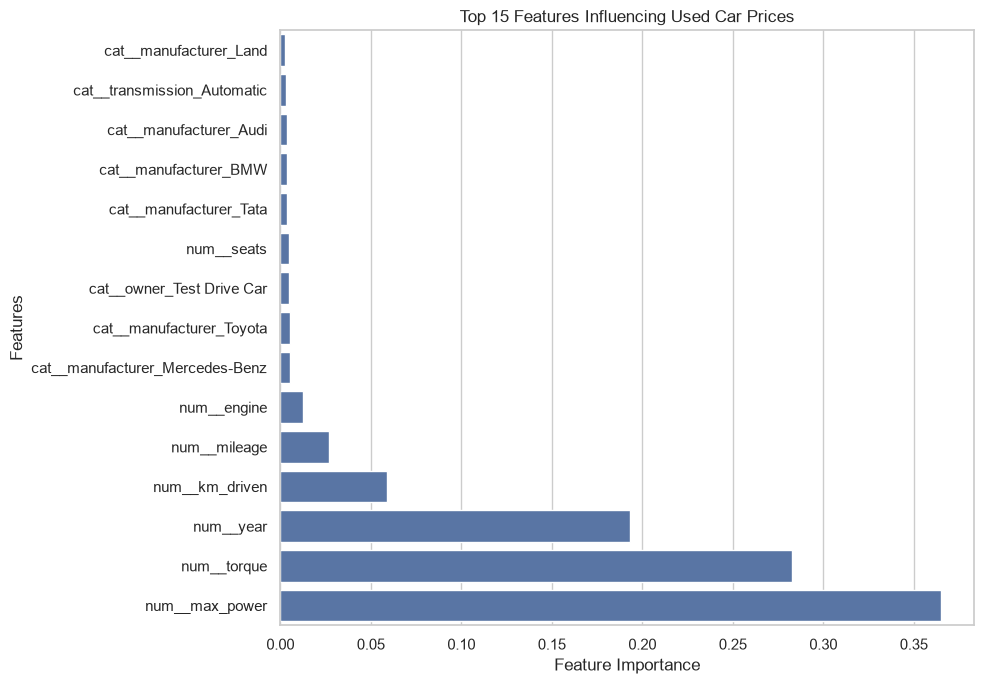

In [114]:
import matplotlib.pyplot as plt
import seaborn as sns

top_features = feature_importance.head(15).sort_values(
    by="Importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Features Influencing Used Car Prices")
plt.xlabel("Feature Importance")
plt.ylabel("Features")

plt.tight_layout()
plt.show()

### **Hyperparameter Tuning**

In [115]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

print("Hyperparameter tuning libraries imported successfully.")

Hyperparameter tuning libraries imported successfully.


In [116]:
param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [10, 15, 20, 25, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "max_features": [0.7, 0.8, 1.0]
}

In [117]:
rf_base = RandomForestRegressor(
    random_state=42,
    n_jobs=-1
)

random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=20,
    cv=5,
    scoring="neg_mean_absolute_error",
    random_state=42,
    n_jobs=-1,
    verbose=2
)

In [118]:
random_search.fit(X_train_processed, y_train)

print("Hyperparameter tuning completed!")

Fitting 5 folds for each of 20 candidates, totalling 100 fits
Hyperparameter tuning completed!


In [119]:
print("Best Hyperparameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(f"₹{-random_search.best_score_:,.2f}")

Best Hyperparameters:
{'n_estimators': 200, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 0.8, 'max_depth': None}

Best Cross-Validation MAE:
₹79,325.53


#### **Random Forest Hyperparameter Tuning**

* Hyperparameter tuning was performed using RandomizedSearchCV with five-fold cross-validation to identify a suitable configuration for the Random Forest Regression model.
* The search evaluated 20 randomly selected hyperparameter combinations using Mean Absolute Error as the evaluation metric.
* The best configuration consisted of 200 estimators, a maximum feature fraction of 0.8, no fixed maximum tree depth, a minimum of 2 samples required for splitting and a minimum of 1 sample per leaf.
* The best cross-validation MAE was ₹79,325.53.
* The tuning process identified a configuration that uses a smaller feature subset for each split, which may improve the diversity of individual trees. The final model will be evaluated on the held-out test dataset to determine whether this configuration improves generalization.


In [120]:
best_rf_model = random_search.best_estimator_

# Generate predictions
y_pred_tuned_rf = best_rf_model.predict(X_test_processed)

print("Tuned Random Forest model trained successfully!")

Tuned Random Forest model trained successfully!


In [121]:
mae_tuned = mean_absolute_error(y_test, y_pred_tuned_rf)

rmse_tuned = np.sqrt(
    mean_squared_error(y_test, y_pred_tuned_rf)
)

r2_tuned = r2_score(y_test, y_pred_tuned_rf)

print("Tuned Random Forest Evaluation")
print("-----------------------------------")
print(f"MAE  : ₹{mae_tuned:,.2f}")
print(f"RMSE : ₹{rmse_tuned:,.2f}")
print(f"R²   : {r2_tuned:.4f}")

Tuned Random Forest Evaluation
-----------------------------------
MAE  : ₹71,183.91
RMSE : ₹139,522.43
R²   : 0.9202


In [122]:
rf_comparison = pd.DataFrame({
    "Model": [
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        mae_rf,
        mae_tuned
    ],
    "RMSE": [
        rmse_rf,
        rmse_tuned
    ],
    "R2 Score": [
        r2_rf,
        r2_tuned
    ]
})

display(rf_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Original Random Forest,71380.9976,138354.4802,0.9216
1,Tuned Random Forest,71183.9084,139522.4332,0.9202


#### **Comparison of Original and Tuned Random Forest Models**

* The original and hyperparameter-tuned Random Forest models were evaluated using the same testing dataset.
* The tuned model achieved an MAE of ₹71,183.91, compared with ₹71,381.00 for the original model. However, the original model achieved a lower RMSE of ₹138,354.48 and a slightly higher R² score of 0.9216.
* The tuned model recorded an RMSE of ₹139,522.43 and an R² score of 0.9202.
* The results indicate that hyperparameter tuning produced only a marginal improvement in MAE while slightly reducing performance according to RMSE and R².
* Therefore, the original Random Forest model is retained as the preferred candidate because it provides a better balance across the evaluation metrics.


### **Final Model Selection and Evaluation**

In [123]:
final_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Original Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        mae,
        mae_tree,
        mae_rf,
        mae_tuned
    ],
    "RMSE": [
        rmse,
        rmse_tree,
        rmse_rf,
        rmse_tuned
    ],
    "R2 Score": [
        r2,
        r2_tree,
        r2_rf,
        r2_tuned
    ]
})

display(final_comparison.round(4))

,Model,MAE,RMSE,R2 Score
0,Linear Regression,134109.0996,263647.0962,0.7152
1,Decision Tree,96463.4922,196234.4156,0.8422
2,Original Random Forest,71380.9976,138354.4802,0.9216
3,Tuned Random Forest,71183.9084,139522.4332,0.9202


#### **Final Model Selection**

* Four regression model configurations were evaluated for used car price prediction: Linear Regression, Decision Tree Regression, Original Random Forest Regression and Tuned Random Forest Regression.
* Among these models, the Original Random Forest achieved the highest R² score of 0.9216 and the lowest RMSE of ₹138,354.48. It also achieved an MAE of ₹71,381.00.
* Although the Tuned Random Forest recorded a slightly lower MAE of ₹71,183.91, its RMSE and R² score were marginally worse than those of the Original Random Forest.
* Considering the overall evaluation metrics, the Original Random Forest Regression model was selected as the preferred model for this project.
* The selected model explains approximately 92.16% of the variation in selling prices on the test dataset, demonstrating strong predictive performance.


## **13. Build the final machine learning pipeline**

### **1. Import Joblib and Pipeline**

In [124]:
import joblib

from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor

print("Required libraries imported successfully.")

Required libraries imported successfully.


### **2. Create the complete pipeline**

In [125]:
final_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", RandomForestRegressor(
            n_estimators=200,
            random_state=42,
            n_jobs=-1
        ))
    ]
)

print("Final machine learning pipeline created successfully.")

Final machine learning pipeline created successfully.


### **3. Train the complete pipeline**

In [126]:
final_model.fit(X_train, y_train)

print("Final model pipeline trained successfully!")

Final model pipeline trained successfully!


### **4. Evaluate the complete pipeline**

In [127]:
final_predictions = final_model.predict(X_test)

final_mae = mean_absolute_error(y_test, final_predictions)
final_rmse = np.sqrt(mean_squared_error(y_test, final_predictions))
final_r2 = r2_score(y_test, final_predictions)

print("Final Model Evaluation")
print("-----------------------------------")
print(f"MAE  : ₹{final_mae:,.2f}")
print(f"RMSE : ₹{final_rmse:,.2f}")
print(f"R²   : {final_r2:.4f}")

Final Model Evaluation
-----------------------------------
MAE  : ₹71,381.00
RMSE : ₹138,354.48
R²   : 0.9216


## **14. Final Model Pipeline**

A complete machine learning pipeline was created by combining the preprocessing operations and the selected Random Forest Regression model.

The pipeline automatically handles missing values, scales numerical features, encodes categorical features and generates selling price predictions.

The complete pipeline was trained using the training dataset and evaluated using the reserved test dataset.

The final evaluation produced the following results:

* **Mean Absolute Error (MAE):** ₹71,381.00
* **Root Mean Squared Error (RMSE):** ₹138,354.48
* **R² Score:** 0.9216

The pipeline achieved the same evaluation results as the original Random Forest model, confirming that the integrated preprocessing and prediction workflow is functioning consistently.

The complete pipeline will be saved using Joblib for future predictions without requiring the preprocessing steps to be performed separately.


In [128]:
from pathlib import Path
import joblib

MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "used_car_price_model.joblib"

joblib.dump(final_model, MODEL_PATH)

print("Model saved successfully!")
print(f"Model location: {MODEL_PATH}")

Model saved successfully!
Model location: c:\Used-Car-Price-Prediction\models\used_car_price_model.joblib


In [129]:
loaded_model = joblib.load(MODEL_PATH)

print("Saved model loaded successfully!")

print("Model type:", type(loaded_model))

Saved model loaded successfully!
Model type: <class 'sklearn.pipeline.Pipeline'>


## **15. Testing the model with new car details**

In [130]:
sample_car = pd.DataFrame([{
    "year": 2018,
    "km_driven": 50000,
    "fuel": "Petrol",
    "seller_type": "Individual",
    "transmission": "Manual",
    "owner": "First Owner",
    "mileage": 18.9,
    "engine": 1197,
    "max_power": 82,
    "torque": 113,
    "seats": 5,
    "manufacturer": "Maruti",
    "mileage_unit": "kmpl"
}])

display(sample_car)

,year,km_driven,fuel,seller_type,transmission,owner,mileage,engine,max_power,torque,seats,manufacturer,mileage_unit
0,2018,50000,Petrol,Individual,Manual,First Owner,18.9,1197,82,113,5,Maruti,kmpl


In [131]:
predicted_price = loaded_model.predict(sample_car)

print("Used Car Price Prediction")
print("-----------------------------")
print(f"Predicted Selling Price: ₹{predicted_price[0]:,.2f}")

Used Car Price Prediction
-----------------------------
Predicted Selling Price: ₹501,389.97


### **Testing the Saved Model with New Vehicle Details Result**

After saving and loading the complete machine learning pipeline, a sample vehicle was provided to test its prediction functionality.
The sample vehicle had the following specifications:

* Manufacturing Year: 2018
* Kilometres Driven: 50,000
* Fuel Type: Petrol
* Seller Type: Individual
* Transmission: Manual
* Ownership: First Owner
* Mileage: 18.9 kmpl
* Engine: 1197 CC
* Maximum Power: 82 bhp
* Torque: 113 Nm
* Seating Capacity: 5
* Manufacturer: Maruti

The saved model successfully processed the vehicle details and generated a predicted selling price of **₹5,01,389.97**.
This test confirms that the saved pipeline can accept new vehicle information and generate predictions without requiring separate preprocessing operations.
